# Integrated Strong-Field QED Pipeline (`src/optics` $\rightarrow$ `.npz` $\rightarrow$ `src/particles`)

End-to-end numerical reproduction of Olofsson & Gonoskov, *"Attaining a strong-field QED signal at laser-electron colliders with optimized focusing"*, Phys. Rev. A **106**, 063512 (2022), coupling the non-paraxial focal-field solver (`src.optics`) to the relativistic electron pusher, LCFA QED emission, and $3\sigma$ collider statistics (`src.particles`) across the schema-validated `.npz` boundary.

### Notebook Sections
1. **Central Parameter Configuration & Laser Presets** — `PAPER_FSQED_LASER` and `UNAL_TISAPPHIRE_LASER` presets, grid settings, and `build_optics_params`.
2. **Eq. (13) Reproduction & Apodizer Efficiency Trade-Off** — Ideal Sheppard–Larkin vs. Gaussian $\times$ super-Gaussian apodizer, far-field overlap (`z-linear` and `circular`), and $w_0 / R_{\max}$ transmission scan.
3. **3D Vectorial Focal Fields & `.npz` Boundary Handoff** — Ideal vs. Gaussian, LP & CP, Paper vs. UNAL Campus field packs round-tripped through `load_field_pack`.
4. **Fig. 4 Reproduction: Aperture Sweep $\kappa_{\mathrm{eff}}(f)$** — Canonical PDF Fig. 4, Paper FSQED Ti:Sapphire, and UNAL Campus Ti:Sapphire across $f \in [0.02, 2.0]$.
5. **Electron Trajectories, $\chi(b, t)$, $F(b)$, & Fig. 2 Phase Space** — Vay pusher dynamics and $(u_\alpha, u_\chi)$ phase space for Gaussian LP, Ideal LP, and Gaussian CP.
6. **Single-Point Strong-Field QED Emission ($\sigma$, $\eta$, $3\sigma$ Shots)** — Paper 1 PW, Paper Sec. V 100 TW benchmark (LP & CP), and UNAL Campus Ti:Sapphire (1 GeV & 10 GeV).
7. **Fig. 5 Reproduction: Numerical $(\varepsilon, P)$ Heatmaps (LP & CP)** — Realistic Gaussian $(\sigma, \eta)$ landscapes via Maxwell power rescaling plus Ideal vs. Gaussian comparison.
8. **Why the UNAL Campus Laser Cannot Reproduce SFQED Detection** — Extended $(\varepsilon, P)$ feasibility map, $3\sigma$ shot-count map, wavelength/jitter sensitivity, and quantitative gap table.

In [1]:
import copy
import math
import sys
import tempfile
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

t_notebook_start = time.perf_counter()

REPO_ROOT = Path.cwd().resolve()
if not (REPO_ROOT / "src").exists():
    REPO_ROOT = REPO_ROOT.parent
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from src.optics import cli, comparison, constants as OC, focus, sweep
from src.particles import (
    FieldChecks,
    FieldPack,
    build_lcfa_table,
    compute_fig2_phase_space,
    compute_high_chi_time_fraction,
    compute_sigma_and_eta,
    estimate_electron_loss_shots,
    estimate_shots_for_confidence,
    evaluate_eb,
    fig4_reference_curve,
    fig5_reference_contours,
    load_field_pack,
    propagate_ensemble,
    sample_electron_batch,
    simulate_qed_ensemble,
    theoretical_chi_max,
)

plt.rcParams.update({
    "figure.dpi": 120,
    "axes.grid": True,
    "grid.alpha": 0.28,
    "axes.spines.top": True,
    "axes.spines.right": True,
    "font.size": 10,
})

print(f"Repository root: {REPO_ROOT}")
print(f"Paper FSQED preset: {OC.PAPER_FSQED_LASER}")
print(f"UNAL Ti:Sapphire preset: {OC.UNAL_TISAPPHIRE_LASER}")
print(f"Paper Fig. 4 preset: {OC.PAPER_FIG4_LASER}")

Repository root: /Users/rifusaki/localRepos/uni/fsqed-laser-electron
Paper FSQED preset: {'lambda0_m': 8e-07, 'power_w': 1000000000000000.0, 'tau_fwhm_s': 1.3342563807926082e-14, 'energy_gev': 1.0}
UNAL Ti:Sapphire preset: {'lambda0_m': 8e-07, 'power_w': 13000.0, 'tau_fwhm_s': 1.7e-13, 'energy_gev': 1.0}
Paper Fig. 4 preset: {'lambda0_m': 1e-06, 'power_w': 1000000000000000.0, 'energy_gev': 1.0}


## 1. Central Parameter Configuration & Laser Presets

We define `PRESETS` directly backed by `OC.PAPER_FSQED_LASER` ($1\ \mathrm{PW}$, $0.8\ \mu\mathrm{m}$, 5 cycles, configured at $\varepsilon_0 = 10\ \mathrm{GeV}$ for Sec. V collider targets) and `OC.UNAL_TISAPPHIRE_LASER` ($13\ \mathrm{kW}$, $0.8\ \mu\mathrm{m}$, $170\ \mathrm{fs}$, $\varepsilon_0 = 1\ \mathrm{GeV}$).

`build_optics_params(cfg, mode, pol="z-linear", account_for_losses=True)` validates all optical inputs upfront and defaults to post-loss focal power accounting in `gaussian` mode (`cli.generate_field_pack` scales focal power by `aperture * apodizer` transmission when `account_for_losses=True`). Both `"z-linear"` and `"circular"` polarizations are supported natively across `src.optics` and `src.particles`.

In [2]:
PRESETS = {
    "fsqed_paper_5cycle": {
        "lambda0_m": float(OC.PAPER_FSQED_LASER["lambda0_m"]),
        "power_w": float(OC.PAPER_FSQED_LASER["power_w"]),
        "n_cycles": 5.0,
        "tau_fwhm_s": float(OC.PAPER_FSQED_LASER["tau_fwhm_s"]),
        "f_number": 0.25,
        "w0_over_rmax": 0.7,
        "apod_order": 8.0,
        "energy_gev": 10.0,
        "n_particles": 1200,
        "sigma_dt_s": 0.0,
        "b_max_lambdas": 1.5,
    },
    "campus_tisapphire": {
        "lambda0_m": float(OC.UNAL_TISAPPHIRE_LASER["lambda0_m"]),
        "power_w": float(OC.UNAL_TISAPPHIRE_LASER["power_w"]),
        "n_cycles": None,
        "tau_fwhm_s": float(OC.UNAL_TISAPPHIRE_LASER["tau_fwhm_s"]),
        "f_number": 0.25,
        "w0_over_rmax": 0.7,
        "apod_order": 8.0,
        "energy_gev": float(OC.UNAL_TISAPPHIRE_LASER["energy_gev"]),
        "n_particles": 400,
        "sigma_dt_s": 0.0,
        "b_max_lambdas": 1.5,
    },
}

ACTIVE_PRESET = "fsqed_paper_5cycle"
OVERRIDES = {}

GRID_SETTINGS = {
    "nx": 40,
    "ny": 40,
    "nz": 40,
    "span_xy_lambdas": 8.0,
    "span_y_lambdas": 5.0,
    "ntheta": 28,
    "nphi": 56,
}


def build_optics_params(
    cfg: dict,
    mode: str,
    *,
    pol: str = "z-linear",
    account_for_losses: bool = True,
    grid_settings: dict | None = None,
) -> dict:
    '''Validate configuration and build a cli.generate_field_pack parameter dict.'''
    if mode not in ("ideal", "gaussian"):
        raise ValueError(f"mode must be 'ideal' or 'gaussian', got {mode!r}")
    if pol not in ("z-linear", "circular"):
        raise ValueError(f"pol must be 'z-linear' or 'circular', got {pol!r}")

    lambda0_m = float(cfg["lambda0_m"])
    power_w = float(cfg["power_w"])
    f_number = float(cfg["f_number"])
    w0_over_rmax = float(cfg["w0_over_rmax"])
    apod_order = float(cfg["apod_order"])
    energy_gev = float(cfg["energy_gev"])
    for name, val in (
        ("lambda0_m", lambda0_m),
        ("power_w", power_w),
        ("f_number", f_number),
        ("w0_over_rmax", w0_over_rmax),
        ("apod_order", apod_order),
        ("energy_gev", energy_gev),
    ):
        if not math.isfinite(val) or val <= 0.0:
            raise ValueError(f"{name} must be finite and positive, got {val}")

    gs = GRID_SETTINGS if grid_settings is None else grid_settings
    n_cycles = cfg.get("n_cycles")
    tau_fwhm_s = cfg.get("tau_fwhm_s")
    if n_cycles is None and tau_fwhm_s is None:
        raise ValueError("Either n_cycles or tau_fwhm_s must be provided in cfg")

    return {
        "lambda0_m": lambda0_m,
        "f_number": f_number,
        "power_w": power_w,
        "pol": pol,
        "tau_fwhm_s": None if tau_fwhm_s is None else float(tau_fwhm_s),
        "n_cycles": None if n_cycles is None else float(n_cycles),
        "energy_gev": energy_gev,
        "mode": mode,
        "w0_over_rmax": w0_over_rmax,
        "apod_order": apod_order,
        "nx": int(gs["nx"]),
        "ny": int(gs["ny"]),
        "nz": int(gs["nz"]),
        "span_xy_m": float(gs["span_xy_lambdas"]) * lambda0_m,
        "span_y_m": float(gs["span_y_lambdas"]) * lambda0_m,
        "ntheta": int(gs["ntheta"]),
        "nphi": int(gs["nphi"]),
        "focal_length_m": None,
        "account_for_losses": bool(account_for_losses),
    }


if ACTIVE_PRESET not in PRESETS:
    raise KeyError(f"Unknown ACTIVE_PRESET {ACTIVE_PRESET!r}")
cfg = copy.deepcopy(PRESETS[ACTIVE_PRESET])
cfg.update(OVERRIDES)

print(f"Active preset: {ACTIVE_PRESET}")
for k, v in cfg.items():
    print(f"  {k:16s}: {v}")

Active preset: fsqed_paper_5cycle
  lambda0_m       : 8e-07
  power_w         : 1000000000000000.0
  n_cycles        : 5.0
  tau_fwhm_s      : 1.3342563807926082e-14
  f_number        : 0.25
  w0_over_rmax    : 0.7
  apod_order      : 8.0
  energy_gev      : 10.0
  n_particles     : 1200
  sigma_dt_s      : 0.0
  b_max_lambdas   : 1.5


## 2. Eq. (13) Reproduction & Apodizer Efficiency Trade-Off (`comparison.py`, `focus.py`)

We compare the ideal Sheppard–Larkin incident radial profile $I^p(R) \propto [(R/2L)^2 + 1]^{-4}$ (Eq. 13) against a collimated Gaussian beam ($\exp[-(R/w_0)^2]$) shaped by a super-Gaussian apodizer ($\exp[-(R/R_{\max})^{2p}]$) via `comparison.incident_intensity_profiles` and `comparison.summarize_degradation`.

We also verify self-consistency of the parabolic-mirror reflection operator: reflecting Eq. (13) (`focus.ideal_far_field`) reproduces `focus.bi_dipole_far_field` (Eqs. 9–10) with normalized overlap $> 0.9999$ for both `"z-linear"` and `"circular"` polarizations. Finally, we scan $w_0 / R_{\max} \in [0.35, 0.5, 0.7, 0.9, 1.2, 1.4]$ to evaluate the throughput-vs.-focusing trade-off using native `comparison` and `sweep` helpers.

Incident profile degradation at f/0.25, w0/R_max=0.7, apod_order=8.0:
  mse                      = 0.297181
  rmse                     = 0.545143
  relative_rmse            = 0.272572
  correlation              = 0.999785
  aperture_transmission    = 0.983120
  transmission             = 0.981961
  total_transmission       = 0.965385
Far-field overlap |<bi_dipole | ideal_far_field>| (z-linear) = 1.00000000
Far-field overlap |<bi_dipole | ideal_far_field>| (circular) = 1.00000000


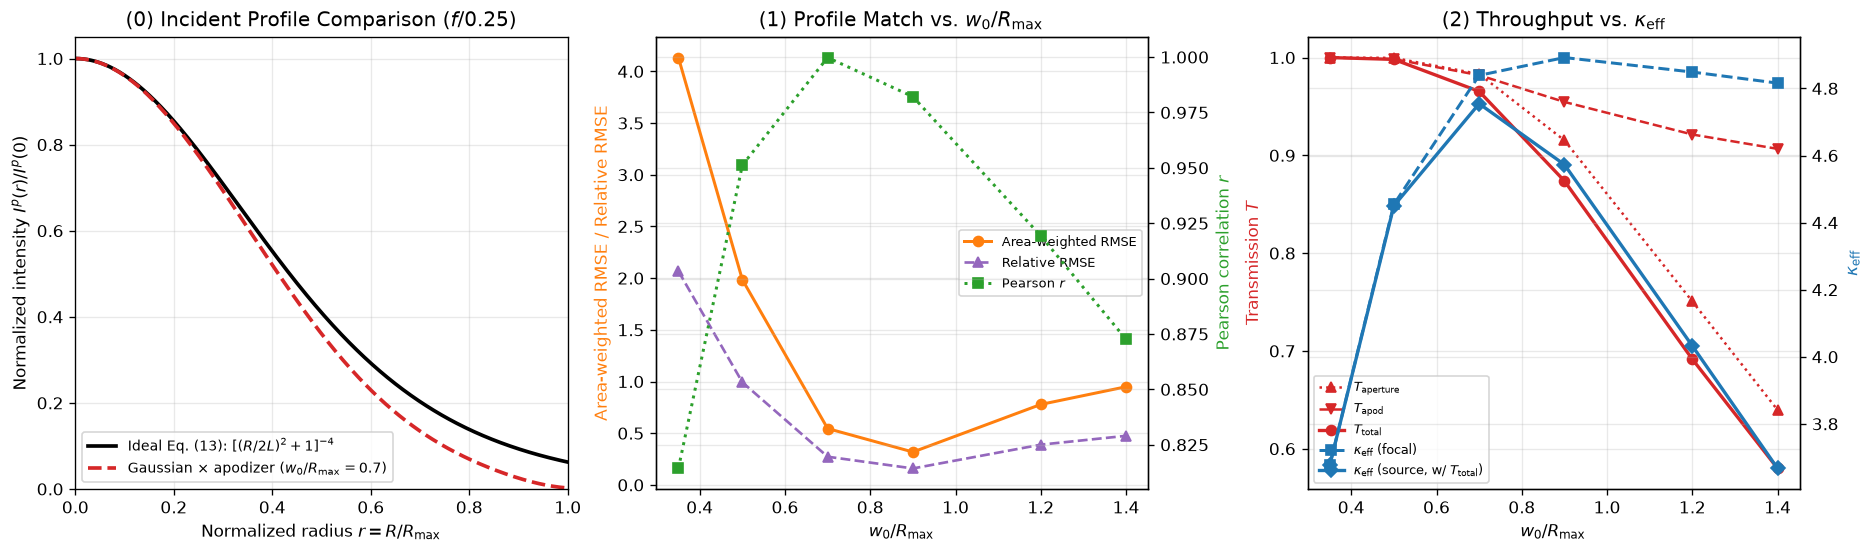

In [3]:
def compute_far_field_overlap(f_number: float, pol: str, *, ntheta: int = 128, nphi: int = 256) -> float:
    '''Normalized solid-angle overlap between focus.ideal_far_field and focus.bi_dipole_far_field.'''
    if not math.isfinite(f_number) or f_number <= 0.0:
        raise ValueError(f"f_number must be finite and positive, got {f_number}")
    if pol not in ("z-linear", "circular"):
        raise ValueError(f"pol must be 'z-linear' or 'circular', got {pol!r}")

    theta_max = focus.f_number_to_theta_max(f_number)
    th_edges = np.linspace(0.0, theta_max, ntheta + 1)
    th = 0.5 * (th_edges[:-1] + th_edges[1:])
    ph = np.linspace(0.0, 2.0 * np.pi, nphi, endpoint=False)
    TH, PH = np.meshgrid(th, ph, indexing="ij")
    n = np.stack([np.sin(TH) * np.cos(PH), -np.cos(TH), np.sin(TH) * np.sin(PH)], axis=-1)
    w = np.sin(TH) * (th_edges[1] - th_edges[0]) * (2.0 * np.pi / nphi)

    e_bi = focus.bi_dipole_far_field(n, pol=pol)
    e_id = focus.ideal_far_field(n, f_number=f_number, pol=pol)

    inner = np.sum(np.sum(np.conj(e_bi) * e_id, axis=-1) * w)
    norm_bi = math.sqrt(float(np.sum(np.sum(np.abs(e_bi) ** 2, axis=-1) * w)))
    norm_id = math.sqrt(float(np.sum(np.sum(np.abs(e_id) ** 2, axis=-1) * w)))
    if norm_bi <= 0.0 or norm_id <= 0.0:
        raise ValueError("Far-field norm must be positive")
    return float(abs(inner) / (norm_bi * norm_id))


R, I_ideal, I_real = comparison.incident_intensity_profiles(
    f_number=cfg["f_number"],
    w0_over_rmax=cfg["w0_over_rmax"],
    apod_order=cfg["apod_order"],
)
deg_report = comparison.summarize_degradation(
    f_number=cfg["f_number"],
    w0_over_rmax=cfg["w0_over_rmax"],
    apod_order=cfg["apod_order"],
)

print(
    f"Incident profile degradation at f/{cfg['f_number']}, "
    f"w0/R_max={cfg['w0_over_rmax']}, apod_order={cfg['apod_order']}:"
)
for key in (
    "mse",
    "rmse",
    "relative_rmse",
    "correlation",
    "aperture_transmission",
    "transmission",
    "total_transmission",
):
    print(f"  {key:24s} = {deg_report[key]:.6f}")

for pol_chk in ("z-linear", "circular"):
    ov = compute_far_field_overlap(cfg["f_number"], pol_chk)
    print(f"Far-field overlap |<bi_dipole | ideal_far_field>| ({pol_chk:8s}) = {ov:.8f}")
    assert ov > 0.9999, f"Overlap check failed for {pol_chk}: {ov}"

w0_scan = [0.35, 0.5, 0.7, 0.9, 1.2, 1.4]
scan_rmse = []
scan_rel_rmse = []
scan_corr = []
scan_t_ap = []
scan_t_apod = []
scan_t_tot = []
scan_kappa_focal = []
scan_kappa_src = []

for w0_ratio in w0_scan:
    rep_w = comparison.summarize_degradation(
        f_number=cfg["f_number"],
        w0_over_rmax=w0_ratio,
        apod_order=cfg["apod_order"],
    )
    t_ap = comparison.aperture_transmission(w0_ratio)
    t_apod = comparison.apodizer_transmission(w0_ratio, cfg["apod_order"])
    t_tot = comparison.total_transmission(w0_ratio, cfg["apod_order"])

    sw_focal = sweep.kappa_eff_vs_f_number(
        [cfg["f_number"]],
        lambda0_m=1.0e-6,
        power_w=1.0e15,
        energy_gev=1.0,
        far_field_builder=sweep.gaussian_far_field_builder(
            w0_over_rmax=w0_ratio, apod_order=cfg["apod_order"]
        ),
        power_transmission=1.0,
        ntheta=128,
        nphi=256,
    )
    sw_src = sweep.kappa_eff_vs_f_number(
        [cfg["f_number"]],
        lambda0_m=1.0e-6,
        power_w=1.0e15,
        energy_gev=1.0,
        far_field_builder=sweep.gaussian_far_field_builder(
            w0_over_rmax=w0_ratio, apod_order=cfg["apod_order"]
        ),
        power_transmission=t_tot,
        ntheta=128,
        nphi=256,
    )
    scan_rmse.append(rep_w["rmse"])
    scan_rel_rmse.append(rep_w["relative_rmse"])
    scan_corr.append(rep_w["correlation"])
    scan_t_ap.append(t_ap)
    scan_t_apod.append(t_apod)
    scan_t_tot.append(t_tot)
    scan_kappa_focal.append(sw_focal[0]["kappa_eff"])
    scan_kappa_src.append(sw_src[0]["kappa_eff"])

I_id_norm = I_ideal / I_ideal[0]
I_re_norm = I_real / I_real[0]

fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.5), constrained_layout=True)

axes[0].plot(R, I_id_norm, "k-", lw=2.2, label=r"Ideal Eq. (13): $[(R/2L)^2 + 1]^{-4}$")
axes[0].plot(
    R,
    I_re_norm,
    "C3--",
    lw=2.2,
    label=rf"Gaussian $\times$ apodizer ($w_0/R_{{\max}}={cfg['w0_over_rmax']}$)",
)
axes[0].set_xlim(0.0, 1.0)
axes[0].set_ylim(0.0, 1.05)
axes[0].set_xlabel(r"Normalized radius $r = R / R_{\max}$")
axes[0].set_ylabel(r"Normalized intensity $I^p(r) / I^p(0)$")
axes[0].set_title(f"(0) Incident Profile Comparison ($f/{cfg['f_number']}$)")
axes[0].legend(fontsize=8.5, loc="lower left")

ax1_r = axes[1].twinx()
l1 = axes[1].plot(w0_scan, scan_rmse, "C1o-", lw=1.8, label="Area-weighted RMSE")
l1b = axes[1].plot(w0_scan, scan_rel_rmse, "C4^--", lw=1.6, label="Relative RMSE")
l2 = ax1_r.plot(w0_scan, scan_corr, "C2s:", lw=1.8, label="Pearson $r$")
axes[1].set_xlabel(r"$w_0 / R_{\max}$")
axes[1].set_ylabel("Area-weighted RMSE / Relative RMSE", color="C1")
ax1_r.set_ylabel("Pearson correlation $r$", color="C2")
axes[1].set_title(r"(1) Profile Match vs. $w_0 / R_{\max}$")
lines_1 = l1 + l1b + l2
axes[1].legend(lines_1, [ln.get_label() for ln in lines_1], loc="center right", fontsize=8)

ax2_r = axes[2].twinx()
l3a = axes[2].plot(w0_scan, scan_t_ap, "C3^:", lw=1.5, label=r"$T_{\mathrm{aperture}}$")
l3b = axes[2].plot(w0_scan, scan_t_apod, "C3v--", lw=1.5, label=r"$T_{\mathrm{apod}}$")
l3c = axes[2].plot(w0_scan, scan_t_tot, "C3o-", lw=2.0, label=r"$T_{\mathrm{total}}$")
l4 = ax2_r.plot(w0_scan, scan_kappa_focal, "C0s--", lw=1.8, label=r"$\kappa_{\mathrm{eff}}$ (focal)")
l5 = ax2_r.plot(w0_scan, scan_kappa_src, "C0D-", lw=2.0, label=r"$\kappa_{\mathrm{eff}}$ (source, w/ $T_{\mathrm{total}}$)")
axes[2].set_xlabel(r"$w_0 / R_{\max}$")
axes[2].set_ylabel("Transmission $T$", color="C3")
ax2_r.set_ylabel(r"$\kappa_{\mathrm{eff}}$", color="C0")
axes[2].set_title(r"(2) Throughput vs. $\kappa_{\mathrm{eff}}$")
lines_2 = l3a + l3b + l3c + l4 + l5
axes[2].legend(lines_2, [ln.get_label() for ln in lines_2], loc="lower left", fontsize=7.5)

plt.show()

## 3. 3D Vectorial Focal Fields & `.npz` Boundary Handoff (Ideal vs. Gaussian, LP & CP, Paper vs. Campus)

We generate six 3D complex phasor field packs (`nx = ny = nz = 40`, `span_xy_lambdas = 8.0`, `span_y_lambdas = 5.0`, `account_for_losses=True` for Gaussian mode) and round-trip each through a `tempfile.TemporaryDirectory()` `.npz` archive via `load_field_pack`:
- **Paper FSQED (1 PW, 0.8 $\mu$m, 5 cycles):** `loaded_gauss_lp`, `loaded_ideal_lp`, `loaded_gauss_cp`, `loaded_ideal_cp`
- **UNAL Campus Ti:Sapphire (13 kW, 0.8 $\mu$m, 170 fs):** `loaded_campus_gauss`, `loaded_campus_ideal`

We verify exact `Ec`/`Bc` array round-trips and `power_conservation_rel_err < 0.10`, print the summary table, and visualize focal ($y=0$) and convergence ($x=0$) $\log_{10}|E|^2$ slices alongside Paper vs. UNAL focal cross-sections.

Pack             |    power_W |     a_max |     chi/GeV |    P_err |  |E(0,0)| [V/m] |  |B(0,0)| [T]
----------------------------------------------------------------------------------------------------


Paper Gauss LP   |  9.654e+14 |  500.8088 |  5.9448e+00 |  1.497% |      2.0099e+15 |    6.7044e+06
Paper Ideal LP   |  1.000e+15 |  517.6688 |  6.1449e+00 |  5.098% |      2.0776e+15 |    6.9301e+06
Paper Gauss CP   |  9.654e+14 |  354.1253 |  4.2036e+00 |  1.497% |      1.4212e+15 |    4.7407e+06
Paper Ideal CP   |  1.000e+15 |  366.0471 |  4.3451e+00 |  5.098% |      1.4691e+15 |    4.9003e+06
UNAL Gauss LP    |  1.255e+04 |    0.0018 |  2.1434e-05 |  1.497% |      7.2469e+09 |    2.4173e+01
UNAL Ideal LP    |  1.300e+04 |    0.0019 |  2.2156e-05 |  5.098% |      7.4909e+09 |    2.4987e+01


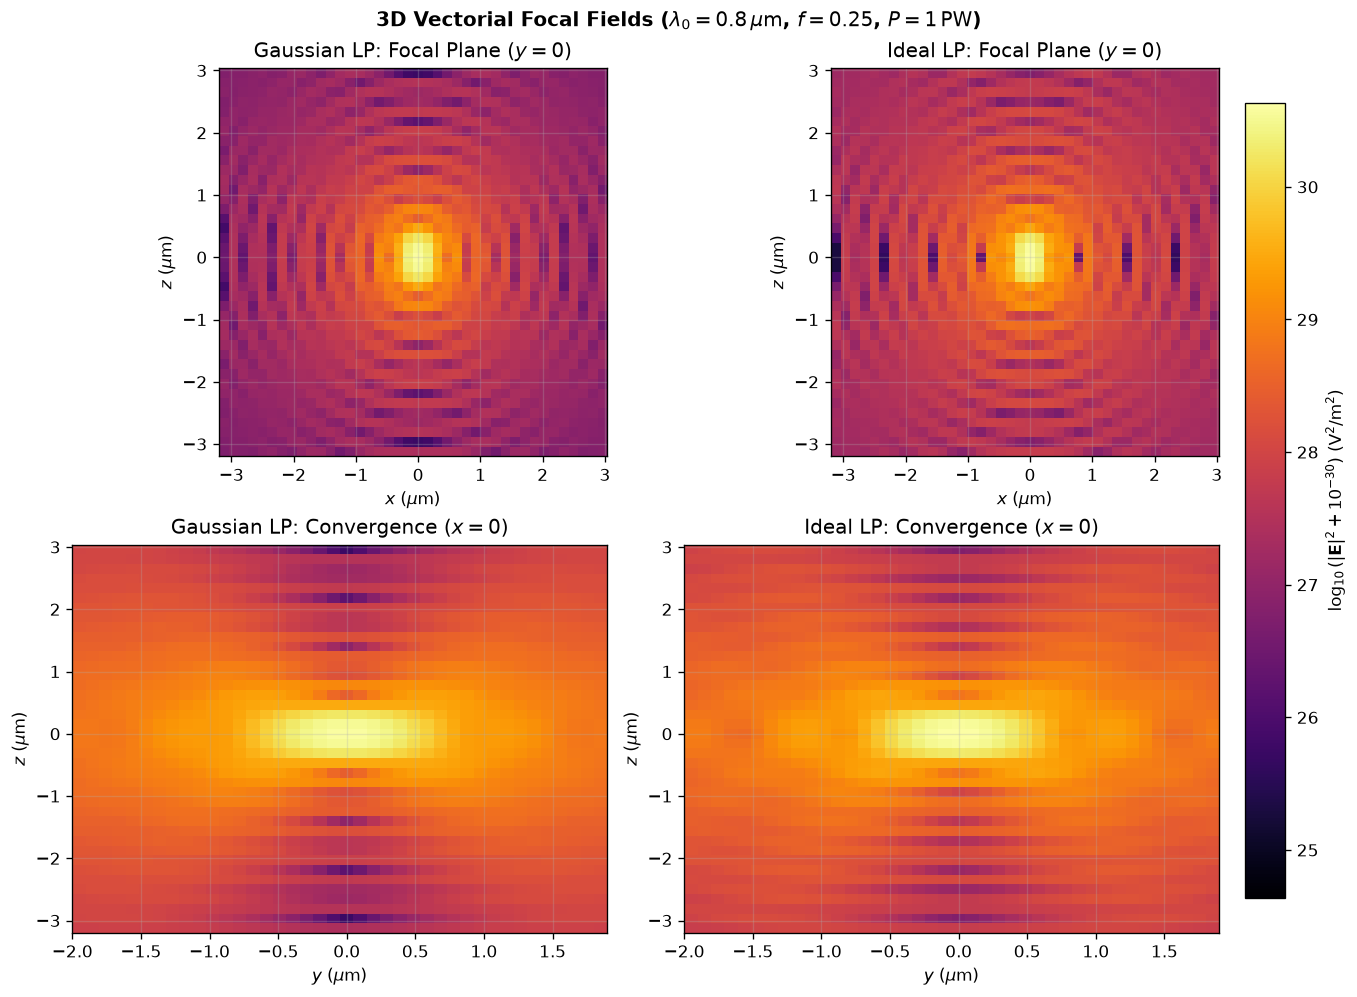

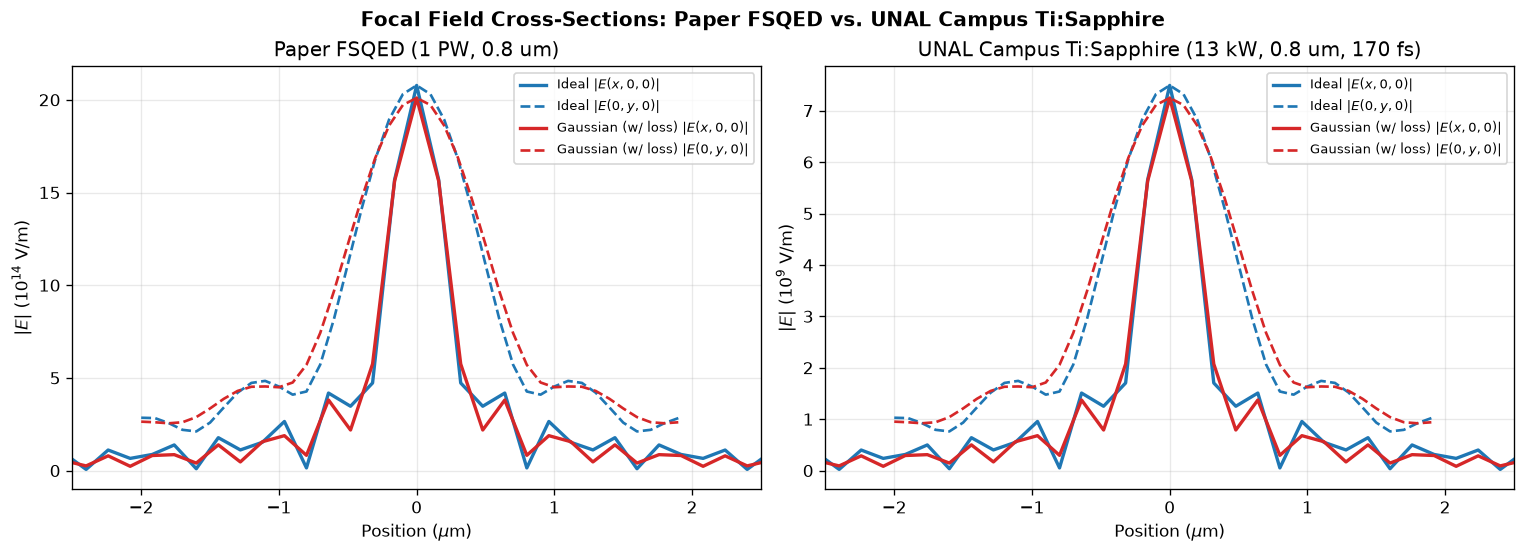

In [4]:
def generate_and_load_pack(cfg_dict: dict, mode: str, *, pol: str = "z-linear", account_for_losses: bool = True) -> tuple[dict, FieldPack]:
    '''Generate a field pack, round-trip via compressed .npz, and verify bit-exactness.'''
    params = build_optics_params(cfg_dict, mode, pol=pol, account_for_losses=account_for_losses)
    raw = cli.generate_field_pack(params)
    with tempfile.TemporaryDirectory() as tmp_dir:
        npz_path = cli.save_field_pack(raw, out_dir=Path(tmp_dir), filename=f"{mode}_{pol}.npz")
        loaded = load_field_pack(npz_path)

    if not np.array_equal(loaded.Ec, raw["Ec"]) or not np.array_equal(loaded.Bc, raw["Bc"]):
        raise AssertionError(f"Round-trip Ec/Bc mismatch for {mode}/{pol}")
    if loaded.checks.power_conservation_rel_err >= 0.10:
        raise AssertionError(
            f"Power conservation error too large ({loaded.checks.power_conservation_rel_err:.4f}) for {mode}/{pol}"
        )
    return raw, loaded


_, loaded_gauss_lp = generate_and_load_pack(cfg, "gaussian", pol="z-linear", account_for_losses=True)
_, loaded_ideal_lp = generate_and_load_pack(cfg, "ideal", pol="z-linear", account_for_losses=False)
_, loaded_gauss_cp = generate_and_load_pack(cfg, "gaussian", pol="circular", account_for_losses=True)
_, loaded_ideal_cp = generate_and_load_pack(cfg, "ideal", pol="circular", account_for_losses=False)

campus_cfg = copy.deepcopy(PRESETS["campus_tisapphire"])
_, loaded_campus_gauss = generate_and_load_pack(campus_cfg, "gaussian", pol="z-linear", account_for_losses=True)
_, loaded_campus_ideal = generate_and_load_pack(campus_cfg, "ideal", pol="z-linear", account_for_losses=False)

pack_catalog = [
    ("Paper Gauss LP", loaded_gauss_lp),
    ("Paper Ideal LP", loaded_ideal_lp),
    ("Paper Gauss CP", loaded_gauss_cp),
    ("Paper Ideal CP", loaded_ideal_cp),
    ("UNAL Gauss LP", loaded_campus_gauss),
    ("UNAL Ideal LP", loaded_campus_ideal),
]

r_origin = np.zeros(3, dtype=np.float64)
header = (
    f"{'Pack':16s} | {'power_W':>10s} | {'a_max':>9s} | {'chi/GeV':>11s} | "
    f"{'P_err':>8s} | {'|E(0,0)| [V/m]':>15s} | {'|B(0,0)| [T]':>13s}"
)
print(header)
print("-" * len(header))
for label, pk in pack_catalog:
    e0, b0 = evaluate_eb(pk, r_origin, 0.0)
    e0_mag = float(np.linalg.norm(e0))
    b0_mag = float(np.linalg.norm(b0))
    print(
        f"{label:16s} | {pk.power_W:10.3e} | {pk.checks.a_max:9.4f} | "
        f"{pk.checks.chi_max_per_GeV:11.4e} | {pk.checks.power_conservation_rel_err:7.3%} | "
        f"{e0_mag:15.4e} | {b0_mag:13.4e}"
    )

iy_mid = loaded_gauss_lp.grid.Ny // 2
ix_mid = loaded_gauss_lp.grid.Nx // 2
iz_mid = loaded_gauss_lp.grid.Nz // 2
x_um = loaded_gauss_lp.grid.x_axis * 1.0e6
y_um = loaded_gauss_lp.grid.y_axis * 1.0e6
z_um = loaded_gauss_lp.grid.z_axis * 1.0e6

ext_xz = [x_um[0], x_um[-1], z_um[0], z_um[-1]]
ext_yz = [y_um[0], y_um[-1], z_um[0], z_um[-1]]

e2_xz_g = np.log10(np.sum(np.abs(loaded_gauss_lp.Ec[0, :, :, iy_mid, :]) ** 2, axis=0) + 1.0e-30)
e2_xz_i = np.log10(np.sum(np.abs(loaded_ideal_lp.Ec[0, :, :, iy_mid, :]) ** 2, axis=0) + 1.0e-30)
e2_yz_g = np.log10(np.sum(np.abs(loaded_gauss_lp.Ec[0, :, :, :, ix_mid]) ** 2, axis=0) + 1.0e-30)
e2_yz_i = np.log10(np.sum(np.abs(loaded_ideal_lp.Ec[0, :, :, :, ix_mid]) ** 2, axis=0) + 1.0e-30)

vmax_hm = float(max(e2_xz_g.max(), e2_xz_i.max(), e2_yz_g.max(), e2_yz_i.max()))
vmin_hm = vmax_hm - 6.0

fig, axes = plt.subplots(2, 2, figsize=(11.2, 8.2), constrained_layout=True)
hm_specs = [
    (axes[0, 0], e2_xz_g, ext_xz, r"$x$ ($\mu$m)", r"$z$ ($\mu$m)", "Gaussian LP: Focal Plane ($y=0$)", "equal"),
    (axes[0, 1], e2_xz_i, ext_xz, r"$x$ ($\mu$m)", r"$z$ ($\mu$m)", "Ideal LP: Focal Plane ($y=0$)", "equal"),
    (axes[1, 0], e2_yz_g, ext_yz, r"$y$ ($\mu$m)", r"$z$ ($\mu$m)", "Gaussian LP: Convergence ($x=0$)", "auto"),
    (axes[1, 1], e2_yz_i, ext_yz, r"$y$ ($\mu$m)", r"$z$ ($\mu$m)", "Ideal LP: Convergence ($x=0$)", "auto"),
]
for ax, arr, ext, xl, yl, title, asp in hm_specs:
    im = ax.imshow(arr, origin="lower", extent=ext, cmap="inferno", vmin=vmin_hm, vmax=vmax_hm, aspect=asp)
    ax.set_xlabel(xl)
    ax.set_ylabel(yl)
    ax.set_title(title)

cbar = fig.colorbar(im, ax=axes, shrink=0.92, pad=0.02)
cbar.set_label(r"$\log_{10}(|\mathbf{E}|^2 + 10^{-30})\ (\mathrm{V^2/m^2})$")
fig.suptitle(r"3D Vectorial Focal Fields ($\lambda_0=0.8\,\mu\mathrm{m}$, $f=0.25$, $P=1\,\mathrm{PW}$)", fontweight="bold")
plt.show()

# 1x2 Paper (10^14 V/m) vs UNAL Campus (10^9 V/m) focal field cross-sections
fig, axes = plt.subplots(1, 2, figsize=(12.6, 4.5), constrained_layout=True)
profile_specs = [
    (axes[0], loaded_ideal_lp, loaded_gauss_lp, 1.0e14, "Paper FSQED (1 PW, 0.8 um)", r"$|E|\ (10^{14}\ \mathrm{V/m})$"),
    (axes[1], loaded_campus_ideal, loaded_campus_gauss, 1.0e9, "UNAL Campus Ti:Sapphire (13 kW, 0.8 um, 170 fs)", r"$|E|\ (10^{9}\ \mathrm{V/m})$"),
]
for ax, pk_id, pk_ga, scale, title, ylab in profile_specs:
    ex_id = np.sqrt(np.sum(np.abs(pk_id.Ec[0, :, iz_mid, iy_mid, :]) ** 2, axis=0)) / scale
    ey_id = np.sqrt(np.sum(np.abs(pk_id.Ec[0, :, iz_mid, :, ix_mid]) ** 2, axis=0)) / scale
    ex_ga = np.sqrt(np.sum(np.abs(pk_ga.Ec[0, :, iz_mid, iy_mid, :]) ** 2, axis=0)) / scale
    ey_ga = np.sqrt(np.sum(np.abs(pk_ga.Ec[0, :, iz_mid, :, ix_mid]) ** 2, axis=0)) / scale

    ax.plot(x_um, ex_id, "C0-", lw=2.0, label=r"Ideal $|E(x, 0, 0)|$")
    ax.plot(y_um, ey_id, "C0--", lw=1.6, label=r"Ideal $|E(0, y, 0)|$")
    ax.plot(x_um, ex_ga, "C3-", lw=2.0, label=r"Gaussian (w/ loss) $|E(x, 0, 0)|$")
    ax.plot(y_um, ey_ga, "C3--", lw=1.6, label=r"Gaussian (w/ loss) $|E(0, y, 0)|$")
    ax.set_xlim(-2.5, 2.5)
    ax.set_xlabel(r"Position ($\mu$m)")
    ax.set_ylabel(ylab)
    ax.set_title(title)
    ax.legend(fontsize=8, loc="upper right")

fig.suptitle("Focal Field Cross-Sections: Paper FSQED vs. UNAL Campus Ti:Sapphire", fontweight="bold")
plt.show()

## 4. Fig. 4 Reproduction: Aperture Sweep $\kappa_{\mathrm{eff}}(f)$ for Paper & UNAL Campus (`sweep.py`, `stats.fig4_reference_curve`)

Using `sweep.default_f_number_sweep()` ($f \in [0.02, 2.0]$, corresponding to opening angles $\zeta \approx 170.85^\circ \rightarrow 14.25^\circ$ via `sweep.f_number_to_opening_angle_deg`), we generate a 3-panel reproduction of Fig. 4 comparing:
- **Panel A:** Canonical PDF Fig. 4 (`OC.PAPER_FIG4_LASER`: $1\ \mathrm{PW}$, $1\ \mu\mathrm{m}$, $1\ \mathrm{GeV}$) — analytic truncated bi-dipole vs. Debye Ideal vs. Realistic Gaussian (focal power and net power with loss $T$).
- **Panel B:** Paper FSQED Ti:Sapphire (`OC.PAPER_FSQED_LASER`: $1\ \mathrm{PW}$, $0.8\ \mu\mathrm{m}$) — Ideal vs. Realistic Gaussian (focal & with loss $T$).
- **Panel C:** UNAL Campus Ti:Sapphire (`OC.UNAL_TISAPPHIRE_LASER`: $13\ \mathrm{kW}$, $0.8\ \mu\mathrm{m}$, $170\ \mathrm{fs}$) — Ideal vs. Realistic Gaussian (left axis in $10^{-5}/\mathrm{GeV}$, right axis in $10^{9}\ \mathrm{V/m}$).

f-number sweep: 25 points in [0.02, 2.00], opening angles 170.85 -> 14.25 deg


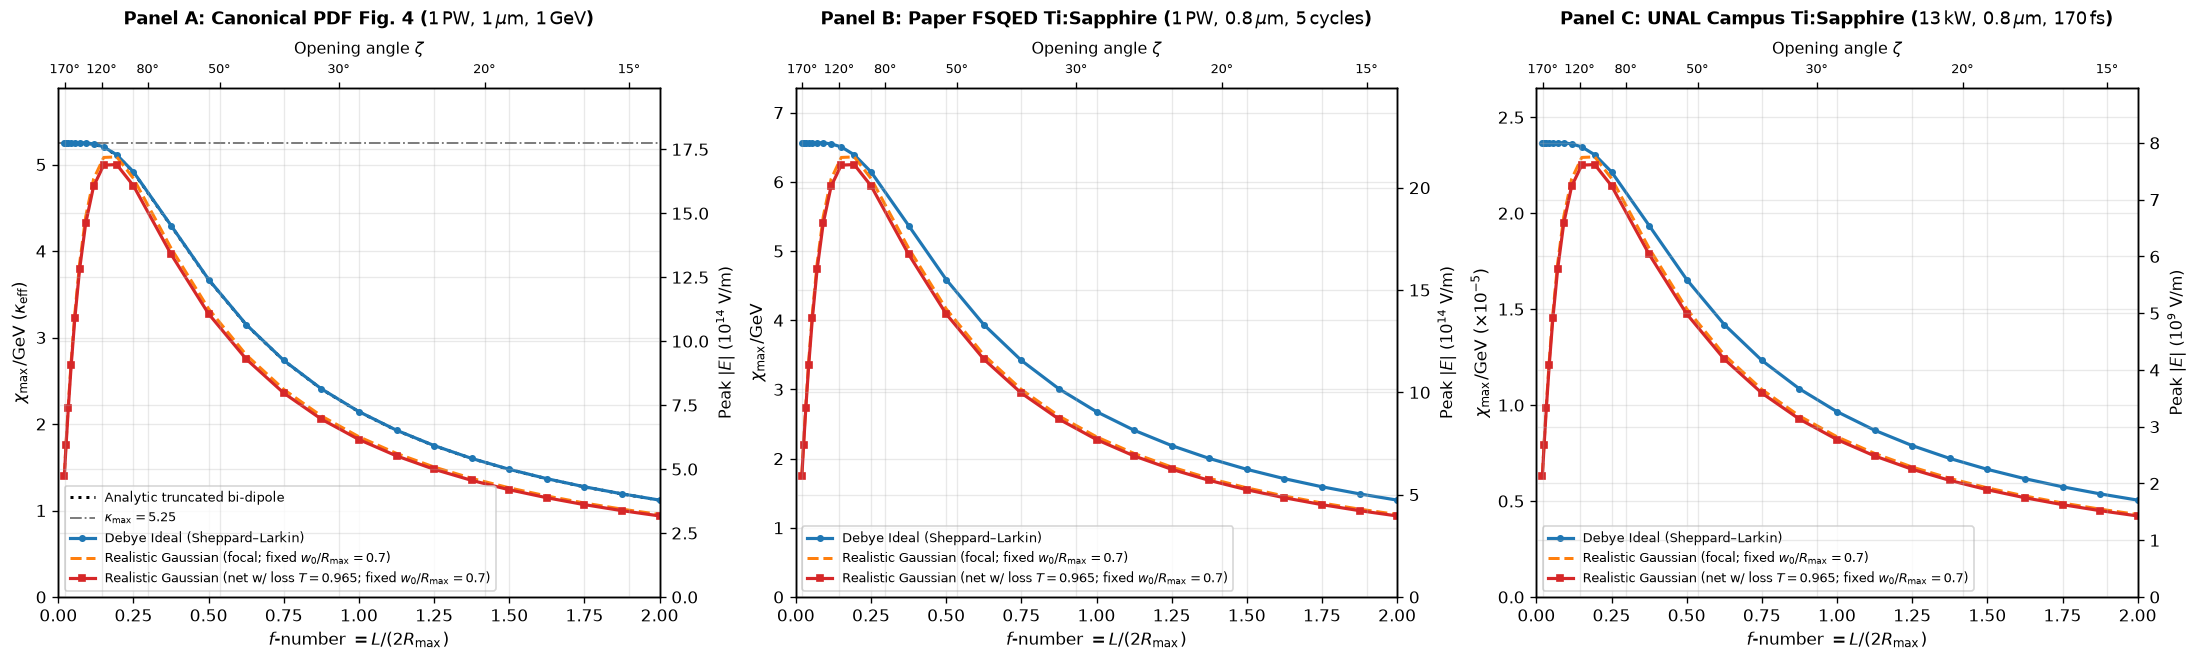

In [5]:
fns = sweep.default_f_number_sweep()
angles_deg = sweep.f_number_to_opening_angle_deg(fns)
print(
    f"f-number sweep: {len(fns)} points in [{fns.min():.2f}, {fns.max():.2f}], "
    f"opening angles {angles_deg.max():.2f} -> {angles_deg.min():.2f} deg"
)

w0_ref = cfg["w0_over_rmax"]
apod_ref = cfg["apod_order"]
t_total_ref = sweep.gaussian_transmission(w0_ref, apod_ref)


def run_aperture_curves(lambda0_m: float, power_w: float, energy_gev: float) -> tuple[list[dict], list[dict], list[dict]]:
    '''Evaluate ideal, lossless-gaussian, and lossy-gaussian kappa_eff sweeps.'''
    ideal = sweep.kappa_eff_vs_f_number(
        fns,
        lambda0_m=lambda0_m,
        power_w=power_w,
        energy_gev=energy_gev,
        far_field_builder=sweep.ideal_far_field_builder(),
        ntheta=160,
        nphi=256,
    )
    gauss_focal = sweep.kappa_eff_vs_f_number(
        fns,
        lambda0_m=lambda0_m,
        power_w=power_w,
        energy_gev=energy_gev,
        far_field_builder=sweep.gaussian_far_field_builder(w0_ref, apod_ref),
        power_transmission=1.0,
        ntheta=160,
        nphi=256,
    )
    gauss_loss = sweep.kappa_eff_vs_f_number(
        fns,
        lambda0_m=lambda0_m,
        power_w=power_w,
        energy_gev=energy_gev,
        far_field_builder=sweep.gaussian_far_field_builder(w0_ref, apod_ref),
        power_transmission=t_total_ref,
        ntheta=160,
        nphi=256,
    )
    return ideal, gauss_focal, gauss_loss


def add_top_opening_angle_axis(ax: plt.Axes) -> plt.Axes:
    '''Attach secondary top x-axis with Fig. 4 opening-angle ticks.'''
    tick_angles = [170, 120, 80, 50, 30, 20, 15]
    tick_fns = [1.0 / (4.0 * math.tan(math.radians(a) / 2.0)) for a in tick_angles]
    ax_top = ax.twiny()
    ax_top.set_xlim(ax.get_xlim())
    ax_top.set_xticks(tick_fns)
    ax_top.set_xticklabels([f"{a}°" for a in tick_angles], fontsize=8)
    ax_top.set_xlabel(r"Opening angle $\zeta$", fontsize=9.5, labelpad=5)
    return ax_top


def add_right_field_axis(ax: plt.Axes, *, yscale: float, exp_e: int, ylabel: str) -> plt.Axes:
    '''Attach right y-axis converting left chi_max/GeV (scaled by yscale) to peak |E|.'''
    chi_to_e = OC.E_CRIT / (2.0 * OC.GAMMA_PER_GEV) / yscale / (10.0 ** exp_e)
    ax_r = ax.twinx()
    y0, y1 = ax.get_ylim()
    ax_r.set_ylim(y0 * chi_to_e, y1 * chi_to_e)
    ax_r.set_ylabel(ylabel, fontsize=9.5)
    return ax_r


ref_fig4 = fig4_reference_curve(
    f_numbers=fns,
    power_w=OC.PAPER_FIG4_LASER["power_w"],
    energy_gev=OC.PAPER_FIG4_LASER["energy_gev"],
    lambda_m=OC.PAPER_FIG4_LASER["lambda0_m"],
)
sw_a_id, sw_a_gf, sw_a_gl = run_aperture_curves(**OC.PAPER_FIG4_LASER)
sw_b_id, sw_b_gf, sw_b_gl = run_aperture_curves(**{k: OC.PAPER_FSQED_LASER[k] for k in ("lambda0_m", "power_w", "energy_gev")})
sw_c_id, sw_c_gf, sw_c_gl = run_aperture_curves(**{k: OC.UNAL_TISAPPHIRE_LASER[k] for k in ("lambda0_m", "power_w", "energy_gev")})

fig, axes = plt.subplots(1, 3, figsize=(18.2, 5.4), constrained_layout=True)

panels_fig4 = [
    (
        axes[0],
        sw_a_id,
        sw_a_gf,
        sw_a_gl,
        ref_fig4["chi_max"],
        1.0,
        14,
        r"Panel A: Canonical PDF Fig. 4 ($1\,\mathrm{PW},\,1\,\mu\mathrm{m},\,1\,\mathrm{GeV}$)",
        r"$\chi_{\max} / \mathrm{GeV}$ ($\kappa_{\mathrm{eff}}$)",
        r"Peak $|E|\ (10^{14}\ \mathrm{V/m})$",
    ),
    (
        axes[1],
        sw_b_id,
        sw_b_gf,
        sw_b_gl,
        None,
        1.0,
        14,
        r"Panel B: Paper FSQED Ti:Sapphire ($1\,\mathrm{PW},\,0.8\,\mu\mathrm{m},\,5\,\mathrm{cycles}$)",
        r"$\chi_{\max} / \mathrm{GeV}$",
        r"Peak $|E|\ (10^{14}\ \mathrm{V/m})$",
    ),
    (
        axes[2],
        sw_c_id,
        sw_c_gf,
        sw_c_gl,
        None,
        1.0e5,
        9,
        r"Panel C: UNAL Campus Ti:Sapphire ($13\,\mathrm{kW},\,0.8\,\mu\mathrm{m},\,170\,\mathrm{fs}$)",
        r"$\chi_{\max} / \mathrm{GeV}\ (\times 10^{-5})$",
        r"Peak $|E|\ (10^{9}\ \mathrm{V/m})$",
    ),
]

for ax, r_id, r_gf, r_gl, ref_y, yscale, exp_e, title, ylab, rylab in panels_fig4:
    y_id = np.array([r["chi_max_per_GeV"] for r in r_id]) * yscale
    y_gf = np.array([r["chi_max_per_GeV"] for r in r_gf]) * yscale
    y_gl = np.array([r["chi_max_per_GeV"] for r in r_gl]) * yscale

    if ref_y is not None:
        ax.plot(fns, ref_y * yscale, "k:", lw=1.8, label="Analytic truncated bi-dipole")
        ax.axhline(OC.KAPPA_BIDIPOLE_MAX, color="0.45", ls="-.", lw=1.1, label=r"$\kappa_{\max}=5.25$")
    ax.plot(fns, y_id, "C0o-", ms=3.2, lw=1.9, label="Debye Ideal (Sheppard–Larkin)")
    ax.plot(fns, y_gf, "C1--", lw=1.8, label=rf"Realistic Gaussian (focal; fixed $w_0/R_{{\max}}={w0_ref}$)")
    ax.plot(fns, y_gl, "C3s-", ms=3.2, lw=1.9, label=rf"Realistic Gaussian (net w/ loss $T={t_total_ref:.3f}$; fixed $w_0/R_{{\max}}={w0_ref}$)")

    ax.set_xlim(0.0, 2.0)
    ax.set_ylim(0.0, float(y_id.max()) * 1.12)
    ax.set_xlabel(r"$f$-number $= L / (2 R_{\max})$")
    ax.set_ylabel(ylab)
    ax.legend(loc="lower left", fontsize=7.5)
    add_top_opening_angle_axis(ax)
    add_right_field_axis(ax, yscale=yscale, exp_e=exp_e, ylabel=rylab)
    ax.set_title(title, fontsize=10.5, fontweight="bold", pad=10)

plt.show()

## 5. Electron Trajectories, $\chi(b,t)$, $F(b)$, & Fig. 2 Phase Space (LP vs. CP, Ideal vs. Gaussian)

We sample an electron ensemble ($p(b) = 2b / b_{\max}^2$) entering along $+\hat{\mathbf{y}}$ from $y_0$ and propagate it using the relativistic Vay pusher through `loaded_gauss_lp` (`signed_alpha=True`), `loaded_ideal_lp` (`signed_alpha=True`), and `loaded_gauss_cp` (`signed_alpha=False`). We inspect $\chi(b, t)$ trajectories, peak $\chi(b)$ and high-$\chi$ residence fraction $F(b)$, the peak-$\chi$ distribution, and the Fig. 2 $(u_\alpha, u_\chi)$ phase space showing the LP ($\pm 0.6$) vs. CP ($0.7$) deviation-angle selection cuts.

Ensemble N=1200, E0=10.0 GeV:
  Gaussian LP: chi_max=59.45, max(peak chi)=57.03, mean F=0.0034
  Ideal LP:    chi_max=61.45, max(peak chi)=58.66, mean F=0.0028
  Gaussian CP: chi_max=42.04, max(peak chi)=40.47, mean F=0.0091


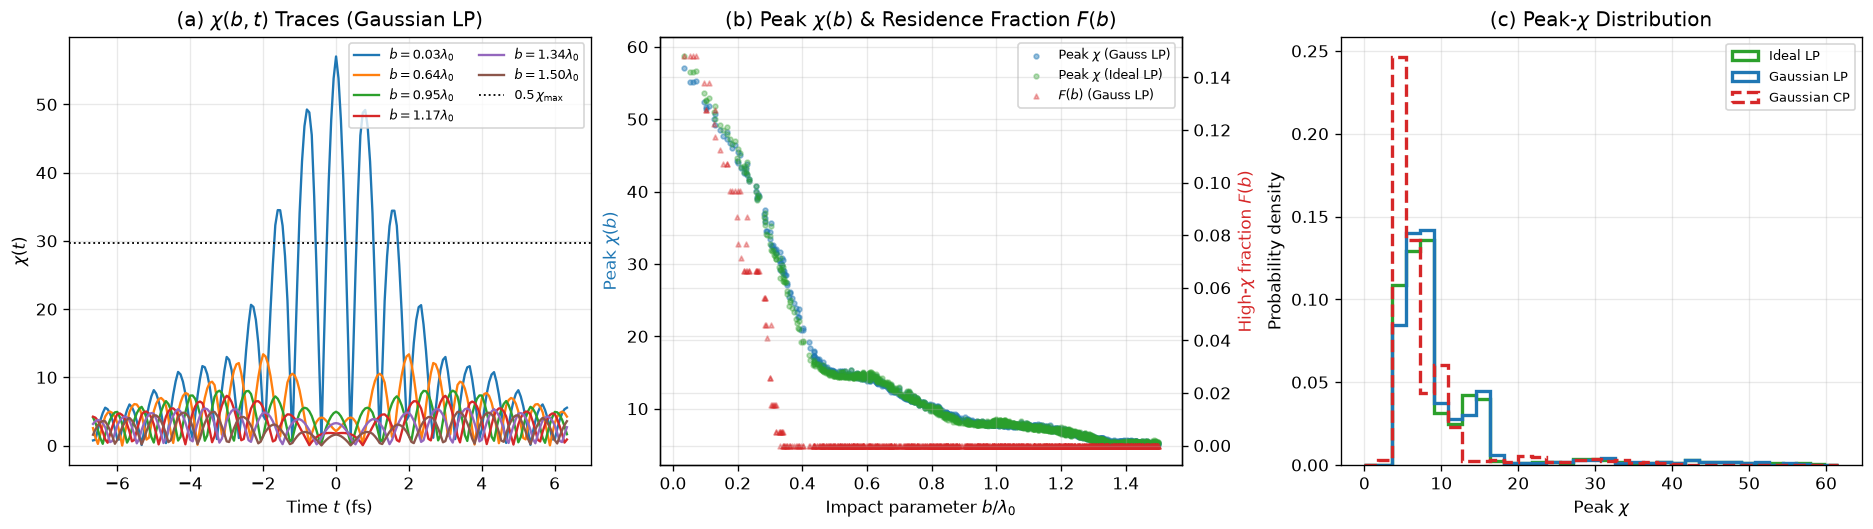

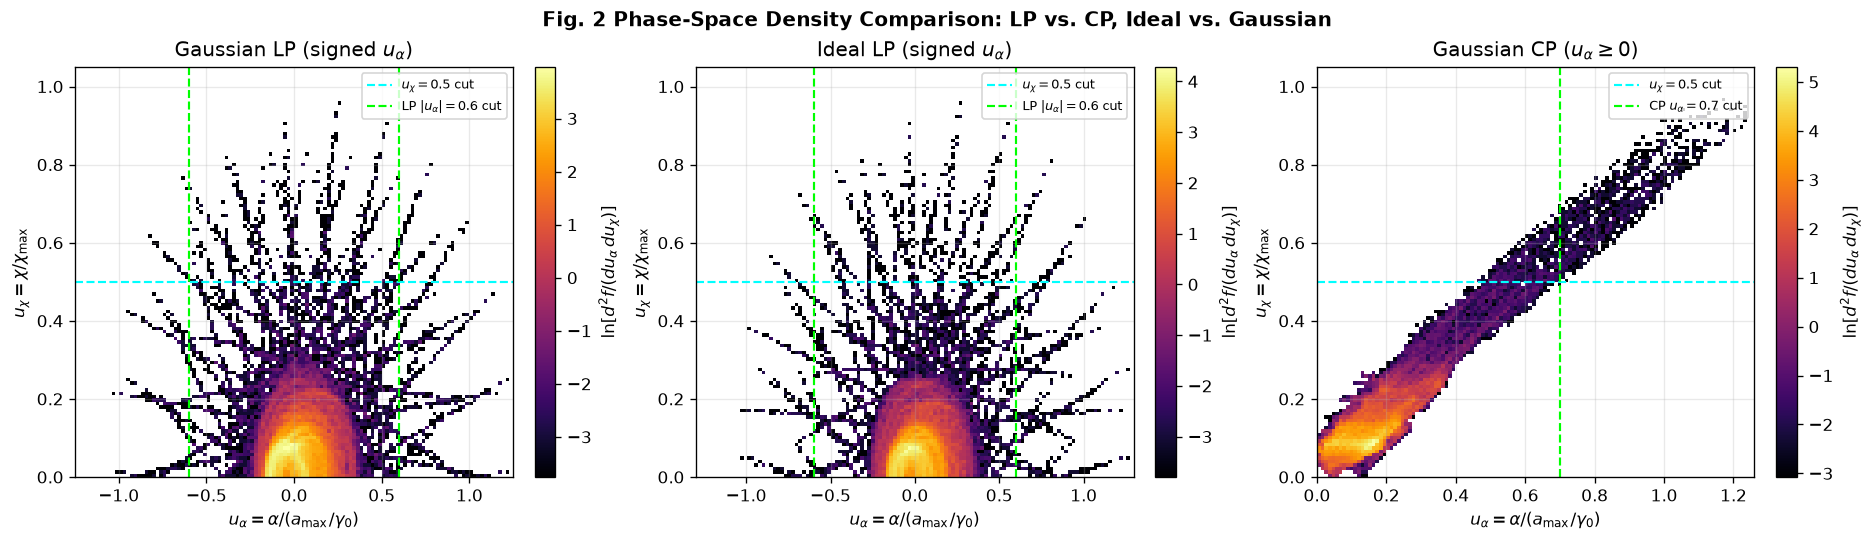

In [6]:
batch_traj = sample_electron_batch(
    n_particles=cfg["n_particles"],
    energy_gev=cfg["energy_gev"],
    b_max_m=cfg["b_max_lambdas"] * loaded_gauss_lp.lambda0_m,
    y0_m=loaded_gauss_lp.grid.y0_m,
    sigma_dt_s=cfg["sigma_dt_s"],
    rng=np.random.default_rng(42),
)

traj_gauss_lp = propagate_ensemble(loaded_gauss_lp, batch_traj, method="vay", signed_alpha=True)
traj_ideal_lp = propagate_ensemble(loaded_ideal_lp, batch_traj, method="vay", signed_alpha=True)
traj_gauss_cp = propagate_ensemble(loaded_gauss_cp, batch_traj, method="vay", signed_alpha=False)

dt_traj_s = float(traj_gauss_lp.t_s[1] - traj_gauss_lp.t_s[0])
chi_max_glp = loaded_gauss_lp.checks.chi_max_per_GeV * cfg["energy_gev"]
chi_max_ilp = loaded_ideal_lp.checks.chi_max_per_GeV * cfg["energy_gev"]
chi_max_gcp = loaded_gauss_cp.checks.chi_max_per_GeV * cfg["energy_gev"]

f_glp = compute_high_chi_time_fraction(traj_gauss_lp.chi, dt_traj_s, chi_max=chi_max_glp)
f_ilp = compute_high_chi_time_fraction(traj_ideal_lp.chi, dt_traj_s, chi_max=chi_max_ilp)
f_gcp = compute_high_chi_time_fraction(traj_gauss_cp.chi, dt_traj_s, chi_max=chi_max_gcp)

peak_chi_glp = np.max(traj_gauss_lp.chi, axis=1)
peak_chi_ilp = np.max(traj_ideal_lp.chi, axis=1)
peak_chi_gcp = np.max(traj_gauss_cp.chi, axis=1)

print(f"Ensemble N={len(batch_traj.b_impact_m)}, E0={cfg['energy_gev']} GeV:")
print(f"  Gaussian LP: chi_max={chi_max_glp:.2f}, max(peak chi)={peak_chi_glp.max():.2f}, mean F={f_glp.mean():.4f}")
print(f"  Ideal LP:    chi_max={chi_max_ilp:.2f}, max(peak chi)={peak_chi_ilp.max():.2f}, mean F={f_ilp.mean():.4f}")
print(f"  Gaussian CP: chi_max={chi_max_gcp:.2f}, max(peak chi)={peak_chi_gcp.max():.2f}, mean F={f_gcp.mean():.4f}")

fig2_glp = compute_fig2_phase_space(
    traj_gauss_lp.alpha,
    traj_gauss_lp.chi,
    a_max=loaded_gauss_lp.checks.a_max,
    gamma0=batch_traj.gamma0,
    chi_max=chi_max_glp,
    signed_alpha=True,
)
fig2_ilp = compute_fig2_phase_space(
    traj_ideal_lp.alpha,
    traj_ideal_lp.chi,
    a_max=loaded_ideal_lp.checks.a_max,
    gamma0=batch_traj.gamma0,
    chi_max=chi_max_ilp,
    signed_alpha=True,
)
fig2_gcp = compute_fig2_phase_space(
    traj_gauss_cp.alpha,
    traj_gauss_cp.chi,
    a_max=loaded_gauss_cp.checks.a_max,
    gamma0=batch_traj.gamma0,
    chi_max=chi_max_gcp,
    signed_alpha=False,
)

# Row 1: chi(b, t), peak chi(b) & F(b), peak-chi distribution
fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.3), constrained_layout=True)

sort_idx = np.argsort(batch_traj.b_impact_m)
sample_indices = sort_idx[np.linspace(0, len(sort_idx) - 1, 6, dtype=int)]
t_fs = traj_gauss_lp.t_s * 1.0e15
for idx in sample_indices:
    b_lam = batch_traj.b_impact_m[idx] / loaded_gauss_lp.lambda0_m
    axes[0].plot(t_fs, traj_gauss_lp.chi[idx], lw=1.4, label=rf"$b={b_lam:.2f}\lambda_0$")
axes[0].axhline(0.5 * chi_max_glp, color="k", ls=":", lw=1.1, label=r"$0.5\,\chi_{\max}$")
axes[0].set_xlabel("Time $t$ (fs)")
axes[0].set_ylabel(r"$\chi(t)$")
axes[0].set_title(r"(a) $\chi(b, t)$ Traces (Gaussian LP)")
axes[0].legend(fontsize=7.5, ncol=2)

b_lam_all = batch_traj.b_impact_m / loaded_gauss_lp.lambda0_m
ax1_r = axes[1].twinx()
axes[1].scatter(b_lam_all, peak_chi_glp, s=8, alpha=0.45, color="C0", label=r"Peak $\chi$ (Gauss LP)")
axes[1].scatter(b_lam_all, peak_chi_ilp, s=8, alpha=0.35, color="C2", label=r"Peak $\chi$ (Ideal LP)")
ax1_r.scatter(b_lam_all, f_glp, s=8, alpha=0.35, color="C3", marker="^", label=r"$F(b)$ (Gauss LP)")
axes[1].set_xlabel(r"Impact parameter $b / \lambda_0$")
axes[1].set_ylabel(r"Peak $\chi(b)$", color="C0")
ax1_r.set_ylabel(r"High-$\chi$ fraction $F(b)$", color="C3")
axes[1].set_title(r"(b) Peak $\chi(b)$ & Residence Fraction $F(b)$")
h1, l1 = axes[1].get_legend_handles_labels()
h2, l2 = ax1_r.get_legend_handles_labels()
axes[1].legend(h1 + h2, l1 + l2, fontsize=7.5, loc="upper right")

bins_chi = np.linspace(0.0, max(peak_chi_ilp.max(), peak_chi_glp.max()) * 1.05, 35)
axes[2].hist(peak_chi_ilp, bins=bins_chi, density=True, histtype="step", lw=2.0, color="C2", label="Ideal LP")
axes[2].hist(peak_chi_glp, bins=bins_chi, density=True, histtype="step", lw=2.0, color="C0", label="Gaussian LP")
axes[2].hist(peak_chi_gcp, bins=bins_chi, density=True, histtype="step", lw=2.0, color="C3", ls="--", label="Gaussian CP")
axes[2].set_xlabel(r"Peak $\chi$")
axes[2].set_ylabel("Probability density")
axes[2].set_title(r"(c) Peak-$\chi$ Distribution")
axes[2].legend(fontsize=8)
plt.show()

# Row 2: Fig. 2 Phase Space comparison (Gaussian LP, Ideal LP, Gaussian CP)
fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.4), constrained_layout=True)
f2_specs = [
    (axes[0], fig2_glp, "Gaussian LP (signed $u_\\alpha$)", True),
    (axes[1], fig2_ilp, "Ideal LP (signed $u_\\alpha$)", True),
    (axes[2], fig2_gcp, "Gaussian CP ($u_\\alpha \\geq 0$)", False),
]
cmap_f2 = plt.cm.inferno.copy()
cmap_f2.set_bad("white")

for ax, f2, title, is_lp in f2_specs:
    im = ax.pcolormesh(
        f2["u_alpha_edges"],
        f2["u_chi_edges"],
        f2["log_density"],
        cmap=cmap_f2,
        shading="auto",
    )
    ax.axhline(0.5, color="cyan", ls="--", lw=1.3, label=r"$u_\chi = 0.5$ cut")
    if is_lp:
        ax.axvline(-0.6, color="lime", ls="--", lw=1.3, label=r"LP $|u_\alpha| = 0.6$ cut")
        ax.axvline(0.6, color="lime", ls="--", lw=1.3)
    else:
        ax.axvline(0.7, color="lime", ls="--", lw=1.3, label=r"CP $u_\alpha = 0.7$ cut")
    ax.set_xlabel(r"$u_\alpha = \alpha / (a_{\max} / \gamma_0)$")
    ax.set_ylabel(r"$u_\chi = \chi / \chi_{\max}$")
    ax.set_title(title)
    ax.legend(fontsize=7.5, loc="upper right")
    fig.colorbar(im, ax=ax, label=r"$\ln[d^2 f / (du_\alpha\,du_\chi)]$")

fig.suptitle("Fig. 2 Phase-Space Density Comparison: LP vs. CP, Ideal vs. Gaussian", fontweight="bold")
plt.show()

## 6. Single-Point Strong-Field QED Emission ($\sigma$, $\eta$, $3\sigma$ Shots): Paper vs. Campus

We build the LCFA emission lookup table (`build_lcfa_table()`) and evaluate `simulate_qed_ensemble(..., mode="weighted", table=table)` across:
1. **Paper 1 PW / 10 GeV** (Ideal LP, Gaussian LP, Ideal CP, Gaussian CP)
2. **Paper Sec. V Benchmark (100 TW / 10 GeV / 5-cycle)** (Ideal LP, Gaussian LP, Ideal CP, Gaussian CP)
3. **UNAL Campus Ti:Sapphire (13 kW / 170 fs)** at both **1 GeV** and **10 GeV** (verifying $\sigma = 0$, $\eta = 0$, zero detectable photons).

Required $3\sigma$ photon-detection shots are computed via `estimate_shots_for_confidence(..., tau_l_s=pack.pulse.tau_fwhm_s)` with safe guards for $\sigma = 0$.

Benchmark Case               |   chi_max | sigma [cm^2] |  eta [%] |  3-sig Shots | e-Loss Shots
------------------------------------------------------------------------------------------------
Paper 1PW/10GeV Ideal LP     | 6.1449e+01 |    3.551e-14 |    14.71 |     29304.34 |     2.25e+11
Paper 1PW/10GeV Gauss LP     | 5.9448e+01 |    2.717e-14 |    14.31 |     40440.46 |     1.05e+11
Paper 1PW/10GeV Ideal CP     | 4.3451e+01 |    3.270e-13 |    99.99 |        68.82 |     1.65e+08
Paper 1PW/10GeV Gauss CP     | 4.2036e+01 |    2.359e-13 |   100.00 |        95.39 |     9.00e+07
Sec.V 100TW/10GeV Ideal LP   | 1.9432e+01 |    1.840e-12 |    16.86 |       430.21 |     1.62e+03
Sec.V 100TW/10GeV Gauss LP   | 1.8799e+01 |    1.768e-12 |    13.14 |       736.88 |     1.14e+03
Sec.V 100TW/10GeV Ideal CP   | 1.3741e+01 |    1.720e-11 |    59.41 |         3.71 |     5.70e+01
Sec.V 100TW/10GeV Gauss CP   | 1.3293e+01 |    1.507e-11 |    49.47 |         6.10 |     4.30e+01
UNAL 13kW/1GeV Gauss L

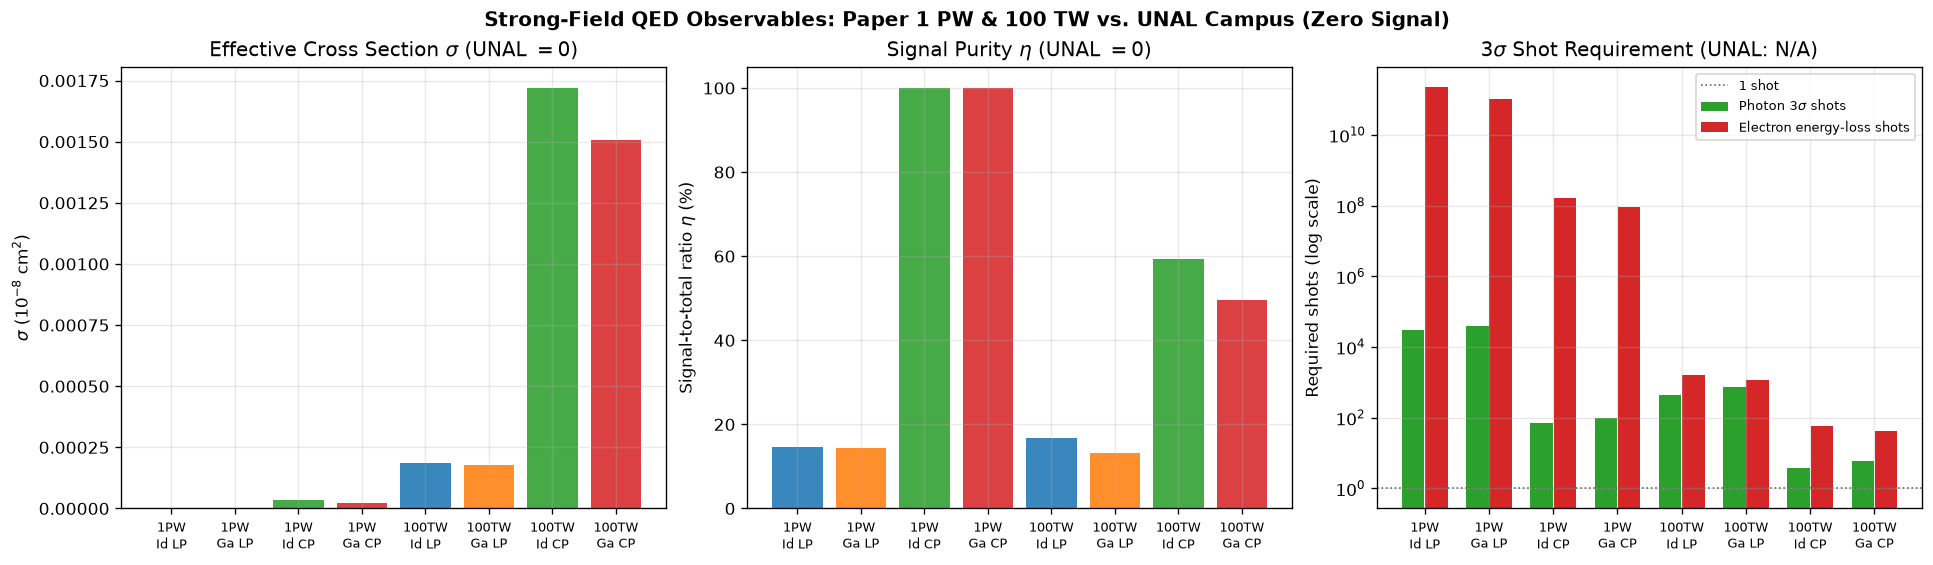

In [7]:
def safe_shot_estimate(metrics: dict[str, float], tau_l_s: float):
    '''Return ShotEstimate when sigma_cm2 > 0 and eta > 0, else None.'''
    if metrics["sigma_cm2"] > 0.0 and metrics["eta"] > 0.0:
        return estimate_shots_for_confidence(
            sigma_cm2=metrics["sigma_cm2"],
            eta=metrics["eta"],
            tau_l_s=tau_l_s,
        )
    return None


def safe_eloss_estimate(chi_max: float, a_max: float) -> float:
    '''Return required electron energy-loss shots, handling extreme survival underflow.'''
    try:
        res = estimate_electron_loss_shots(chi=chi_max, a_max=a_max)
        return float(res["shots_required"])
    except ZeroDivisionError:
        return float("inf")


def evaluate_qed_point(
    pack: FieldPack,
    *,
    energy_gev: float,
    n_particles: int,
    b_max_lambdas: float,
    table,
    seed: int = 42,
) -> dict:
    '''Run weighted LCFA simulation and compute sigma, eta, and shot requirements.'''
    batch = sample_electron_batch(
        n_particles=n_particles,
        energy_gev=energy_gev,
        b_max_m=b_max_lambdas * pack.lambda0_m,
        y0_m=pack.grid.y0_m,
        sigma_dt_s=0.0,
        rng=np.random.default_rng(seed),
    )
    qed = simulate_qed_ensemble(pack, batch, mode="weighted", table=table)
    chi_max = pack.checks.chi_max_per_GeV * energy_gev
    metrics = compute_sigma_and_eta(
        qed.photons,
        pol=pack.pol,
        a_max=pack.checks.a_max,
        chi_max=chi_max,
        b_max_m=batch.b_max_m,
        n_electrons=len(batch.b_impact_m),
    )
    shots = safe_shot_estimate(metrics, tau_l_s=pack.pulse.tau_fwhm_s)
    eloss_shots = safe_eloss_estimate(chi_max, pack.checks.a_max)
    return {
        "chi_max": chi_max,
        "a_max": pack.checks.a_max,
        "sigma_cm2": metrics["sigma_cm2"],
        "eta": metrics["eta"],
        "w_total": metrics["w_total"],
        "w_signal": metrics["w_signal"],
        "n_shots": None if shots is None else shots.n_shots_required,
        "eloss_shots": eloss_shots,
    }


table = build_lcfa_table()

# Generate 100 TW Sec. V benchmark packs (40^3, 5-cycle, 0.8 um, f/0.25)
cfg_100tw = copy.deepcopy(PRESETS["fsqed_paper_5cycle"])
cfg_100tw["power_w"] = 100.0e12
_, loaded_100tw_ideal_lp = generate_and_load_pack(cfg_100tw, "ideal", pol="z-linear", account_for_losses=False)
_, loaded_100tw_gauss_lp = generate_and_load_pack(cfg_100tw, "gaussian", pol="z-linear", account_for_losses=True)
_, loaded_100tw_ideal_cp = generate_and_load_pack(cfg_100tw, "ideal", pol="circular", account_for_losses=False)
_, loaded_100tw_gauss_cp = generate_and_load_pack(cfg_100tw, "gaussian", pol="circular", account_for_losses=True)

qed_cases = [
    ("Paper 1PW/10GeV Ideal LP", loaded_ideal_lp, 10.0, 1200),
    ("Paper 1PW/10GeV Gauss LP", loaded_gauss_lp, 10.0, 1200),
    ("Paper 1PW/10GeV Ideal CP", loaded_ideal_cp, 10.0, 1200),
    ("Paper 1PW/10GeV Gauss CP", loaded_gauss_cp, 10.0, 1200),
    ("Sec.V 100TW/10GeV Ideal LP", loaded_100tw_ideal_lp, 10.0, 1200),
    ("Sec.V 100TW/10GeV Gauss LP", loaded_100tw_gauss_lp, 10.0, 1200),
    ("Sec.V 100TW/10GeV Ideal CP", loaded_100tw_ideal_cp, 10.0, 1200),
    ("Sec.V 100TW/10GeV Gauss CP", loaded_100tw_gauss_cp, 10.0, 1200),
    ("UNAL 13kW/1GeV Gauss LP", loaded_campus_gauss, 1.0, 400),
    ("UNAL 13kW/10GeV Gauss LP", loaded_campus_gauss, 10.0, 400),
]

qed_summary = []
for name, pk, e_gev, n_p in qed_cases:
    res = evaluate_qed_point(pk, energy_gev=e_gev, n_particles=n_p, b_max_lambdas=1.5, table=table)
    res["name"] = name
    qed_summary.append(res)

# Assert UNAL zero detectable photons
for r in qed_summary[-2:]:
    assert r["sigma_cm2"] == 0.0 and r["eta"] == 0.0, f"Expected zero SFQED signal for {r['name']}"

hdr = (
    f"{'Benchmark Case':28s} | {'chi_max':>9s} | {'sigma [cm^2]':>12s} | "
    f"{'eta [%]':>8s} | {'3-sig Shots':>12s} | {'e-Loss Shots':>12s}"
)
print(hdr)
print("-" * len(hdr))
for r in qed_summary:
    shots_str = "N/A (sig=0)" if r["n_shots"] is None else f"{r['n_shots']:12.2f}"
    if r["chi_max"] < 0.1:
        eloss_str = "N/A (no rad)"
    elif not math.isfinite(r["eloss_shots"]):
        eloss_str = "inf"
    else:
        eloss_str = f"{r['eloss_shots']:12.2e}"
    print(
        f"{r['name']:28s} | {r['chi_max']:9.4e} | {r['sigma_cm2']:12.3e} | "
        f"{100.0 * r['eta']:8.2f} | {shots_str:>12s} | {eloss_str:>12s}"
    )

# Bar chart comparison across the 8 Paper/Sec.V cases (plus UNAL annotated as 0)
plot_cases = qed_summary[:8]
x_idx = np.arange(len(plot_cases))
short_labels = [
    "1PW\nId LP", "1PW\nGa LP", "1PW\nId CP", "1PW\nGa CP",
    "100TW\nId LP", "100TW\nGa LP", "100TW\nId CP", "100TW\nGa CP",
]
colors = ["C0", "C1", "C2", "C3", "C0", "C1", "C2", "C3"]

fig, axes = plt.subplots(1, 3, figsize=(16.0, 4.6), constrained_layout=True)

axes[0].bar(x_idx, [r["sigma_cm2"] * 1.0e8 for r in plot_cases], color=colors, alpha=0.88)
axes[0].set_xticks(x_idx, short_labels, fontsize=8)
axes[0].set_ylabel(r"$\sigma\ (10^{-8}\ \mathrm{cm}^2)$")
axes[0].set_title(r"Effective Cross Section $\sigma$ (UNAL $= 0$)")

axes[1].bar(x_idx, [100.0 * r["eta"] for r in plot_cases], color=colors, alpha=0.88)
axes[1].set_xticks(x_idx, short_labels, fontsize=8)
axes[1].set_ylabel(r"Signal-to-total ratio $\eta$ (%)")
axes[1].set_title(r"Signal Purity $\eta$ (UNAL $= 0$)")

photon_shots = [r["n_shots"] if r["n_shots"] is not None else np.nan for r in plot_cases]
eloss_shots = [r["eloss_shots"] if math.isfinite(r["eloss_shots"]) else np.nan for r in plot_cases]
axes[2].bar(x_idx - 0.18, photon_shots, width=0.35, color="C2", log=True, label=r"Photon $3\sigma$ shots")
axes[2].bar(x_idx + 0.18, eloss_shots, width=0.35, color="C3", log=True, label="Electron energy-loss shots")
axes[2].axhline(1.0, color="0.4", ls=":", lw=1.0, label="1 shot")
axes[2].set_xticks(x_idx, short_labels, fontsize=8)
axes[2].set_ylabel("Required shots (log scale)")
axes[2].set_title(r"$3\sigma$ Shot Requirement (UNAL: N/A)")
axes[2].legend(fontsize=8)

fig.suptitle("Strong-Field QED Observables: Paper 1 PW & 100 TW vs. UNAL Campus (Zero Signal)", fontweight="bold")
plt.show()

## 7. Fig. 5 Reproduction: Numerical $(\varepsilon, P)$ Heatmaps for (a) Linear & (b) Circular Polarization (Ideal vs. Realistic Gaussian)

By Maxwell linearity, the spatial field structure at fixed wavelength, $f$-number, and polarization scales strictly as $\sqrt{P / P_0}$. We define a pure helper `rescale_field_pack_power(pack: FieldPack, power_w: float) -> FieldPack` and evaluate the full $14 \times 12$ $(\varepsilon, P)$ grid ($\varepsilon \in [0.1, 1000]\ \mathrm{GeV}$, $P \in [10^{11}, 10^{16}]\ \mathrm{W}$) over four $32^3$ base packs: `(gaussian, z-linear)`, `(gaussian, circular)`, `(ideal, z-linear)`, and `(ideal, circular)`.

For `gaussian` packs at source power $P_{\mathrm{src}}$, focal power is $P_{\mathrm{focal}} = P_{\mathrm{src}} T_{\mathrm{total}}$ so Ideal vs. Realistic Gaussian curves compare at equal source laser power.

Fig. 5 4x(12x14) scan completed in 27.30 s


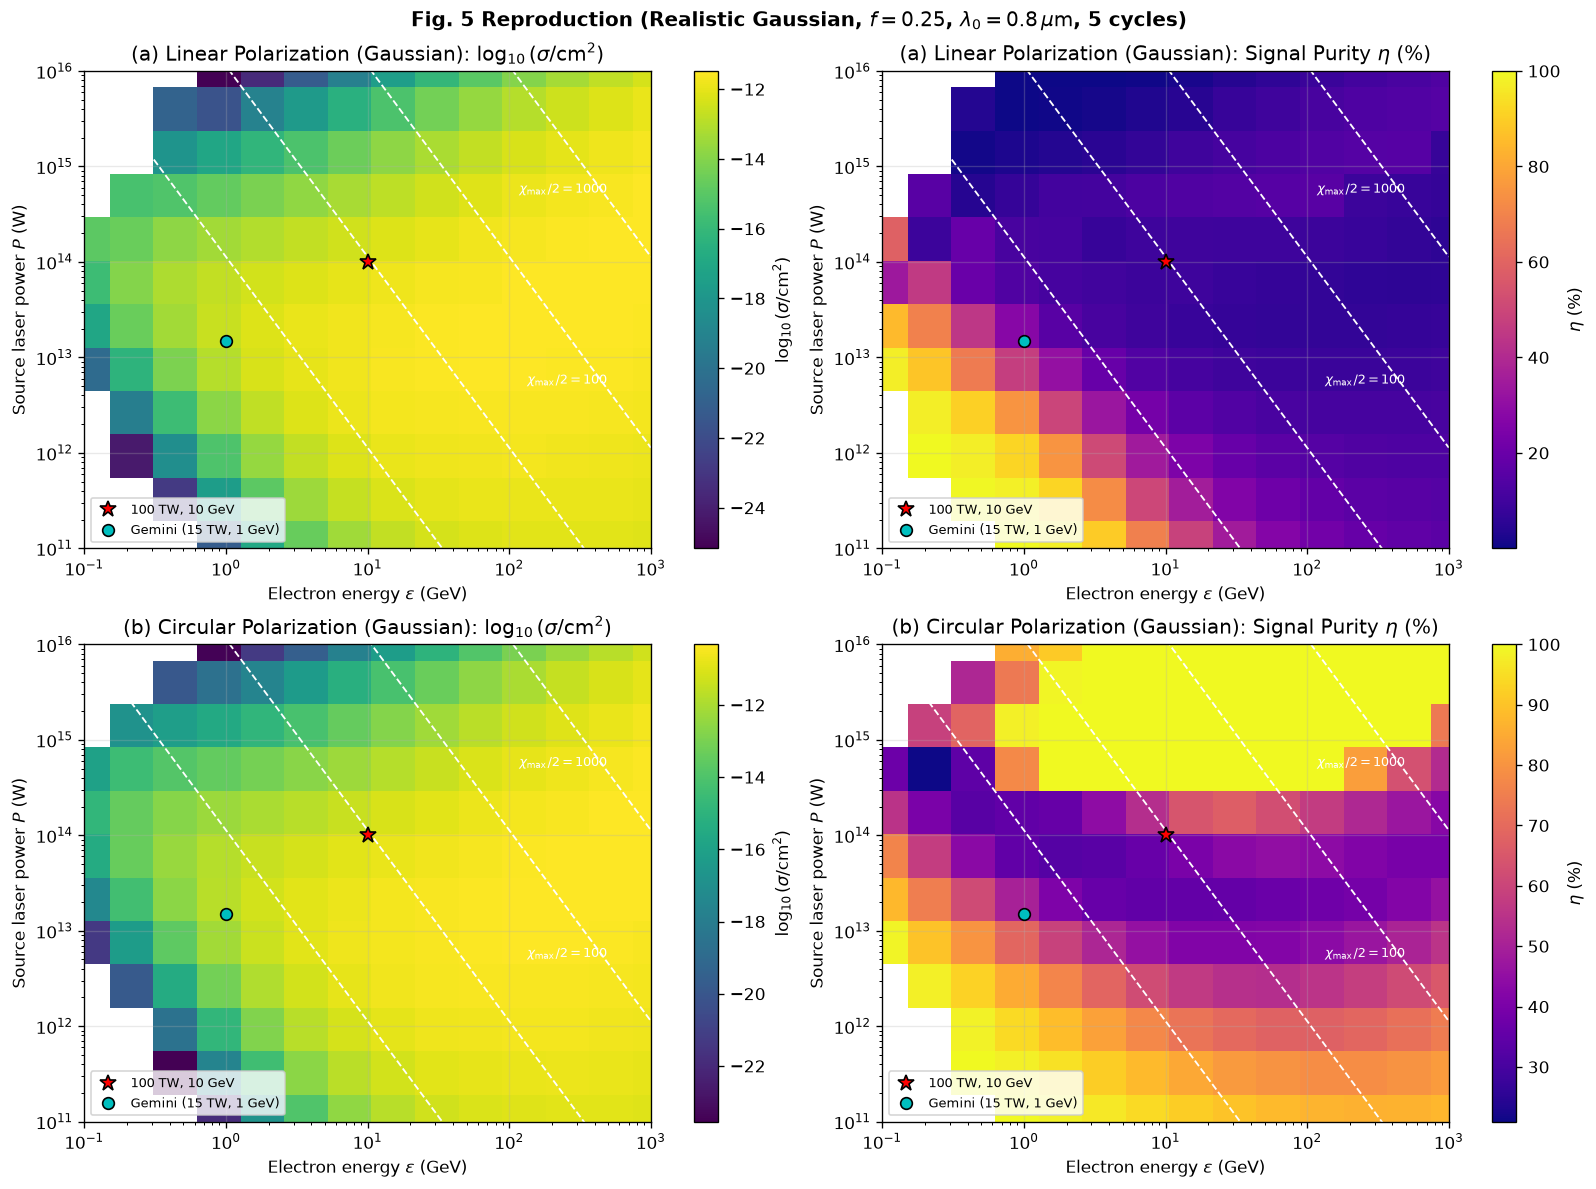

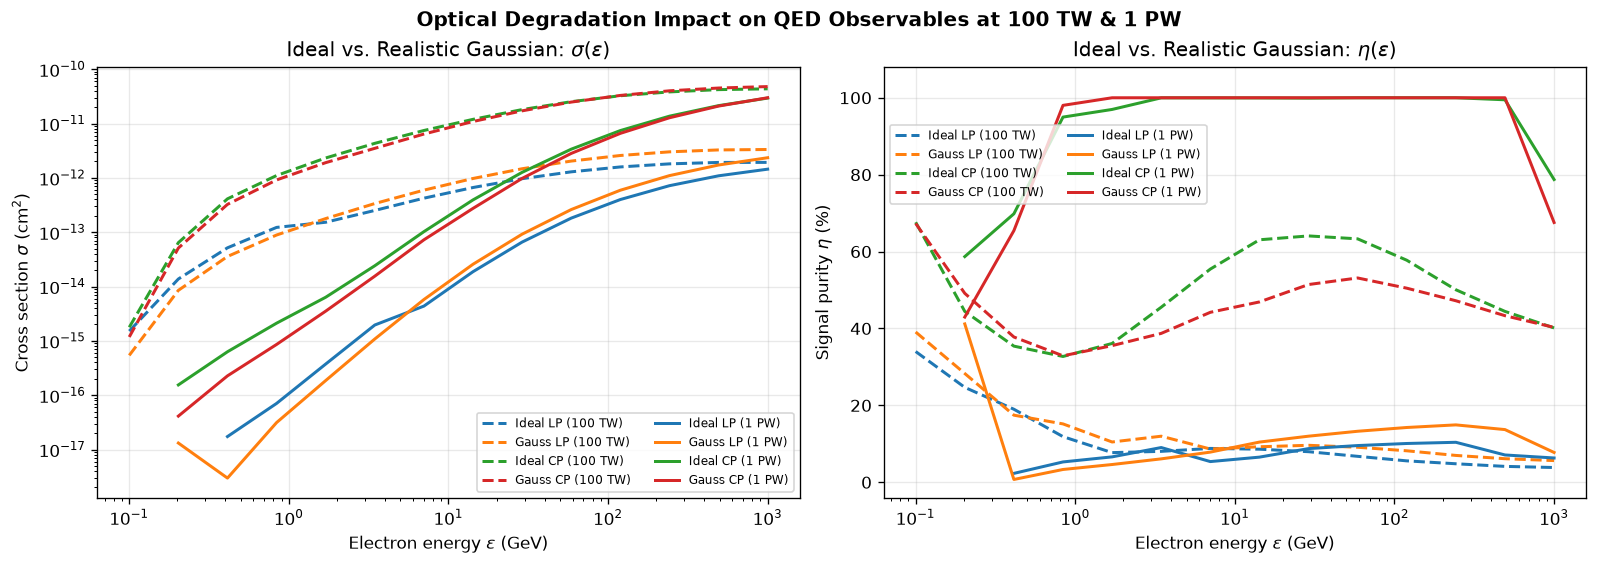

In [8]:
def rescale_field_pack_power(pack: FieldPack, power_w: float) -> FieldPack:
    '''Return a new FieldPack rescaled to focal power_w by Maxwell linearity (sqrt(P/P0)).'''
    if not isinstance(pack, FieldPack):
        raise TypeError(f"pack must be a FieldPack, got {type(pack).__name__}")
    if not math.isfinite(power_w) or power_w <= 0.0:
        raise ValueError(f"power_w must be finite and positive, got {power_w}")

    scale = math.sqrt(float(power_w) / pack.power_W)
    new_checks = FieldChecks(
        a_max=pack.checks.a_max * scale,
        a_max_expected=pack.checks.a_max_expected * scale,
        chi_max_per_GeV=pack.checks.chi_max_per_GeV * scale,
        power_conservation_rel_err=pack.checks.power_conservation_rel_err,
        max_location_m=pack.checks.max_location_m,
    )
    meta_copy = copy.deepcopy(pack.metadata_raw)
    meta_copy["power_W"] = float(power_w)
    meta_copy["checks"]["a_max"] = new_checks.a_max
    meta_copy["checks"]["a_max_expected"] = new_checks.a_max_expected
    meta_copy["checks"]["chi_max_per_GeV"] = new_checks.chi_max_per_GeV
    return FieldPack(
        Ec=pack.Ec * scale,
        Bc=pack.Bc * scale,
        grid=pack.grid,
        freqs=pack.freqs,
        power_W=float(power_w),
        f_number=pack.f_number,
        lambda0_m=pack.lambda0_m,
        pol=pack.pol,
        pulse=pack.pulse,
        checks=new_checks,
        metadata_raw=meta_copy,
    )


fig5_grid_settings = {
    "nx": 32,
    "ny": 32,
    "nz": 32,
    "span_xy_lambdas": 8.0,
    "span_y_lambdas": 5.0,
    "ntheta": 24,
    "nphi": 48,
}
fig5_base_cfg = copy.deepcopy(PRESETS["fsqed_paper_5cycle"])

def build_fig5_base_pack(mode: str, pol: str) -> FieldPack:
    params = build_optics_params(
        fig5_base_cfg,
        mode,
        pol=pol,
        account_for_losses=(mode == "gaussian"),
        grid_settings=fig5_grid_settings,
    )
    raw = cli.generate_field_pack(params)
    with tempfile.TemporaryDirectory() as tmp_d:
        p = cli.save_field_pack(raw, out_dir=Path(tmp_d), filename=f"base_{mode}_{pol}.npz")
        return load_field_pack(p)


base_packs = {
    ("gaussian", "z-linear"): build_fig5_base_pack("gaussian", "z-linear"),
    ("gaussian", "circular"): build_fig5_base_pack("gaussian", "circular"),
    ("ideal", "z-linear"): build_fig5_base_pack("ideal", "z-linear"),
    ("ideal", "circular"): build_fig5_base_pack("ideal", "circular"),
}

eps_scan = np.geomspace(0.1, 1000.0, 14)
p_scan = np.geomspace(1.0e11, 1.0e16, 12)
b_max_fig5 = 1.5 * 0.8e-6
t_loss_fig5 = comparison.total_transmission(fig5_base_cfg["w0_over_rmax"], fig5_base_cfg["apod_order"])

t_scan_start = time.perf_counter()
scan_results = {}
for (mode_k, pol_k), base_pk in base_packs.items():
    sigma_grid = np.zeros((p_scan.size, eps_scan.size), dtype=np.float64)
    eta_grid = np.zeros((p_scan.size, eps_scan.size), dtype=np.float64)
    loss_factor = t_loss_fig5 if mode_k == "gaussian" else 1.0

    for ip, p_src in enumerate(p_scan):
        pk_scaled = rescale_field_pack_power(base_pk, float(p_src) * loss_factor)
        for ie, eps_val in enumerate(eps_scan):
            batch_s = sample_electron_batch(
                n_particles=128,
                energy_gev=float(eps_val),
                b_max_m=b_max_fig5,
                y0_m=pk_scaled.grid.y0_m,
                sigma_dt_s=0.0,
                rng=np.random.default_rng(42),
            )
            qed_s = simulate_qed_ensemble(pk_scaled, batch_s, mode="weighted", table=table)
            m_s = compute_sigma_and_eta(
                qed_s.photons,
                pol=pk_scaled.pol,
                a_max=pk_scaled.checks.a_max,
                chi_max=pk_scaled.checks.chi_max_per_GeV * float(eps_val),
                b_max_m=batch_s.b_max_m,
                n_electrons=len(batch_s.b_impact_m),
            )
            sigma_grid[ip, ie] = m_s["sigma_cm2"]
            eta_grid[ip, ie] = m_s["eta"]
    scan_results[(mode_k, pol_k)] = {"sigma_cm2": sigma_grid, "eta": eta_grid}

print(f"Fig. 5 4x(12x14) scan completed in {time.perf_counter() - t_scan_start:.2f} s")

# Extract effective kappa for realistic Gaussian LP (for chi_max/2 contour overlay)
pk_glp_base = base_packs[("gaussian", "z-linear")]
kappa_eff_fig5 = pk_glp_base.checks.chi_max_per_GeV / (
    math.sqrt((pk_glp_base.power_W / t_loss_fig5) / 1.0e15) * (1.0e-6 / pk_glp_base.lambda0_m)
)
contours_fig5 = fig5_reference_contours(
    energy_gev_grid=eps_scan,
    power_w_grid=p_scan,
    lambda_m=0.8e-6,
    kappa=kappa_eff_fig5,
)

# Plot 2x2 Fig. 5 Reproduction (Realistic Gaussian)
fig, axes = plt.subplots(2, 2, figsize=(13.2, 9.8), constrained_layout=True)
cmap_sig = plt.cm.viridis.copy()
cmap_sig.set_bad("white")
cmap_eta = plt.cm.plasma.copy()
cmap_eta.set_bad("white")

row_specs = [
    (0, "z-linear", "(a) Linear Polarization (Gaussian)"),
    (1, "circular", "(b) Circular Polarization (Gaussian)"),
]

for row_i, pol_k, row_label in row_specs:
    sig = scan_results[("gaussian", pol_k)]["sigma_cm2"]
    eta_pct = 100.0 * scan_results[("gaussian", pol_k)]["eta"]
    log_sig = np.ma.masked_where(sig <= 0.0, np.log10(np.where(sig > 0.0, sig, 1.0)))
    eta_masked = np.ma.masked_where(sig <= 0.0, eta_pct)

    for col_j, data, cmap, cbar_lbl, title_suffix in (
        (0, log_sig, cmap_sig, r"$\log_{10}(\sigma / \mathrm{cm}^2)$", r"$\log_{10}(\sigma / \mathrm{cm}^2)$"),
        (1, eta_masked, cmap_eta, r"$\eta$ (%)", r"Signal Purity $\eta$ (%)"),
    ):
        ax = axes[row_i, col_j]
        im = ax.pcolormesh(eps_scan, p_scan, data, cmap=cmap, shading="auto")
        for lvl_idx, lvl in enumerate(contours_fig5["levels"]):
            ax.plot(
                eps_scan,
                contours_fig5["contour_power_w"][lvl_idx],
                color="white",
                ls="--",
                lw=1.1,
            )
            # Label near right/top edge if inside axis
            p_lbl = contours_fig5["contour_power_w"][lvl_idx, -2]
            if p_scan.min() <= p_lbl <= p_scan.max():
                ax.text(
                    eps_scan[-2],
                    p_lbl * 1.12,
                    rf"$\chi_{{\max}}/2={int(lvl)}$",
                    color="white",
                    fontsize=7.5,
                    ha="right",
                )
        ax.plot(10.0, 100.0e12, "r*", ms=10, markeredgecolor="k", label="100 TW, 10 GeV")
        ax.plot(1.0, 15.0e12, "co", ms=7, markeredgecolor="k", label="Gemini (15 TW, 1 GeV)")
        ax.set_xscale("log")
        ax.set_yscale("log")
        ax.set_xlim(eps_scan.min(), eps_scan.max())
        ax.set_ylim(p_scan.min(), p_scan.max())
        ax.set_xlabel(r"Electron energy $\varepsilon$ (GeV)")
        ax.set_ylabel(r"Source laser power $P$ (W)")
        ax.set_title(f"{row_label}: {title_suffix}")
        ax.legend(fontsize=7.5, loc="lower left")
        fig.colorbar(im, ax=ax, label=cbar_lbl)

fig.suptitle(r"Fig. 5 Reproduction (Realistic Gaussian, $f=0.25$, $\lambda_0=0.8\,\mu\mathrm{m}$, 5 cycles)", fontweight="bold")
plt.show()

# Plot 1x2 Ideal vs Realistic Gaussian comparison at P = 100 TW and P = 1 PW
curve_powers = [(100.0e12, "100 TW", "--"), (1.0e15, "1 PW", "-")]
fig, axes = plt.subplots(1, 2, figsize=(13.2, 4.6), constrained_layout=True)

for p_val, p_lbl, ls in curve_powers:
    for (mode_k, pol_k), color, m_lbl in (
        (("ideal", "z-linear"), "C0", "Ideal LP"),
        (("gaussian", "z-linear"), "C1", "Gauss LP"),
        (("ideal", "circular"), "C2", "Ideal CP"),
        (("gaussian", "circular"), "C3", "Gauss CP"),
    ):
        base_pk = base_packs[(mode_k, pol_k)]
        loss_factor = t_loss_fig5 if mode_k == "gaussian" else 1.0
        pk_p = rescale_field_pack_power(base_pk, p_val * loss_factor)
        sig_curve = np.zeros(eps_scan.size)
        eta_curve = np.zeros(eps_scan.size)
        for ie, eps_val in enumerate(eps_scan):
            b_c = sample_electron_batch(
                n_particles=128,
                energy_gev=float(eps_val),
                b_max_m=b_max_fig5,
                y0_m=pk_p.grid.y0_m,
                sigma_dt_s=0.0,
                rng=np.random.default_rng(42),
            )
            q_c = simulate_qed_ensemble(pk_p, b_c, mode="weighted", table=table)
            m_c = compute_sigma_and_eta(
                q_c.photons,
                pol=pk_p.pol,
                a_max=pk_p.checks.a_max,
                chi_max=pk_p.checks.chi_max_per_GeV * float(eps_val),
                b_max_m=b_c.b_max_m,
                n_electrons=len(b_c.b_impact_m),
            )
            sig_curve[ie] = m_c["sigma_cm2"]
            eta_curve[ie] = 100.0 * m_c["eta"]
        lbl = f"{m_lbl} ({p_lbl})"
        pos = sig_curve > 0.0
        if np.any(pos):
            axes[0].loglog(eps_scan[pos], sig_curve[pos], color=color, ls=ls, lw=1.8, label=lbl)
            axes[1].semilogx(eps_scan[pos], eta_curve[pos], color=color, ls=ls, lw=1.8, label=lbl)

axes[0].set_xlabel(r"Electron energy $\varepsilon$ (GeV)")
axes[0].set_ylabel(r"Cross section $\sigma$ ($\mathrm{cm}^2$)")
axes[0].set_title(r"Ideal vs. Realistic Gaussian: $\sigma(\varepsilon)$")
axes[0].legend(fontsize=7.2, ncol=2, loc="lower right")

axes[1].set_xlabel(r"Electron energy $\varepsilon$ (GeV)")
axes[1].set_ylabel(r"Signal purity $\eta$ (%)")
axes[1].set_title(r"Ideal vs. Realistic Gaussian: $\eta(\varepsilon)$")
axes[1].set_ylim(-4, 108)
axes[1].legend(fontsize=7.2, ncol=2, loc="upper left", bbox_to_anchor=(0.0, 0.88))

fig.suptitle("Optical Degradation Impact on QED Observables at 100 TW & 1 PW", fontweight="bold")
plt.show()

## 8. Why the UNAL Campus Laser Cannot Reproduce SFQED Detection (Fig. 5-Style Feasibility Map & Parameter Gap)

We bring together the complete experimental gap analysis comparing UNAL's campus Ti:Sapphire laser ($13\ \mathrm{kW}$, $0.8\ \mu\mathrm{m}$, $170\ \mathrm{fs}$) against the SFQED detection regime:
- **Panel A — Extended $(\varepsilon, P)$ SFQED Feasibility Heatmap** ($P \in [10^3, 10^{17}]\ \mathrm{W}$, $\varepsilon \in [0.1, 10^3]\ \mathrm{GeV}$): delineates the undetectable/classical QED regime ($\chi_{\max}/2 < 0.1$) from the detectable SFQED signal regime ($\chi_{\max}/2 \ge 1$), marking UNAL ($13\ \mathrm{kW}$ at $1\ \mathrm{GeV}$ and $10\ \mathrm{GeV}$), LUXE ($16.5\ \mathrm{GeV}$, $350\ \mathrm{TW}$), Paper $100\ \mathrm{TW}\text{–}10\ \mathrm{GeV}$, and $1\ \mathrm{PW}\text{–}10\ \mathrm{GeV}$.
- **Panel B — $3\sigma$ Shot-Count Detection Feasibility Heatmap** ($\log_{10} N_{\mathrm{shots}}$) from Section 7's Realistic Gaussian CP $(\sigma, \eta)$ grid via `estimate_shots_for_confidence`.
- **Panel C — Wavelength Tuning ($390\text{–}1040\ \mathrm{nm}$) & Timing Jitter Sensitivity** ($\sigma_{\Delta t} / \tau_{\mathrm{FWHM}} \in [0, 0.25, 0.5, 1.0]$ on `loaded_gauss_lp`).
- **Quantitative Feasibility Gap Table** summarizing $\chi_{\max}$, the LCFA high-energy photon tail $P(\delta > 0.5 \mid \chi_{\max})$, $\sigma$, $\eta$, $N_{\mathrm{shots}}$, $P_{\mathrm{req}} / P_{\mathrm{UNAL}}$, and $\varepsilon_{\mathrm{req}}$.

UNAL 13 kW gap (kappa_eff_net=4.756): P_req(10 GeV)/P_UNAL = 8.70e+07x, P_req(1 GeV)/P_UNAL = 8.70e+09x, eps_req(13 kW) = 93.30 TeV
Wavelength tuning 800 nm -> 390 nm gain factor: 2.05x


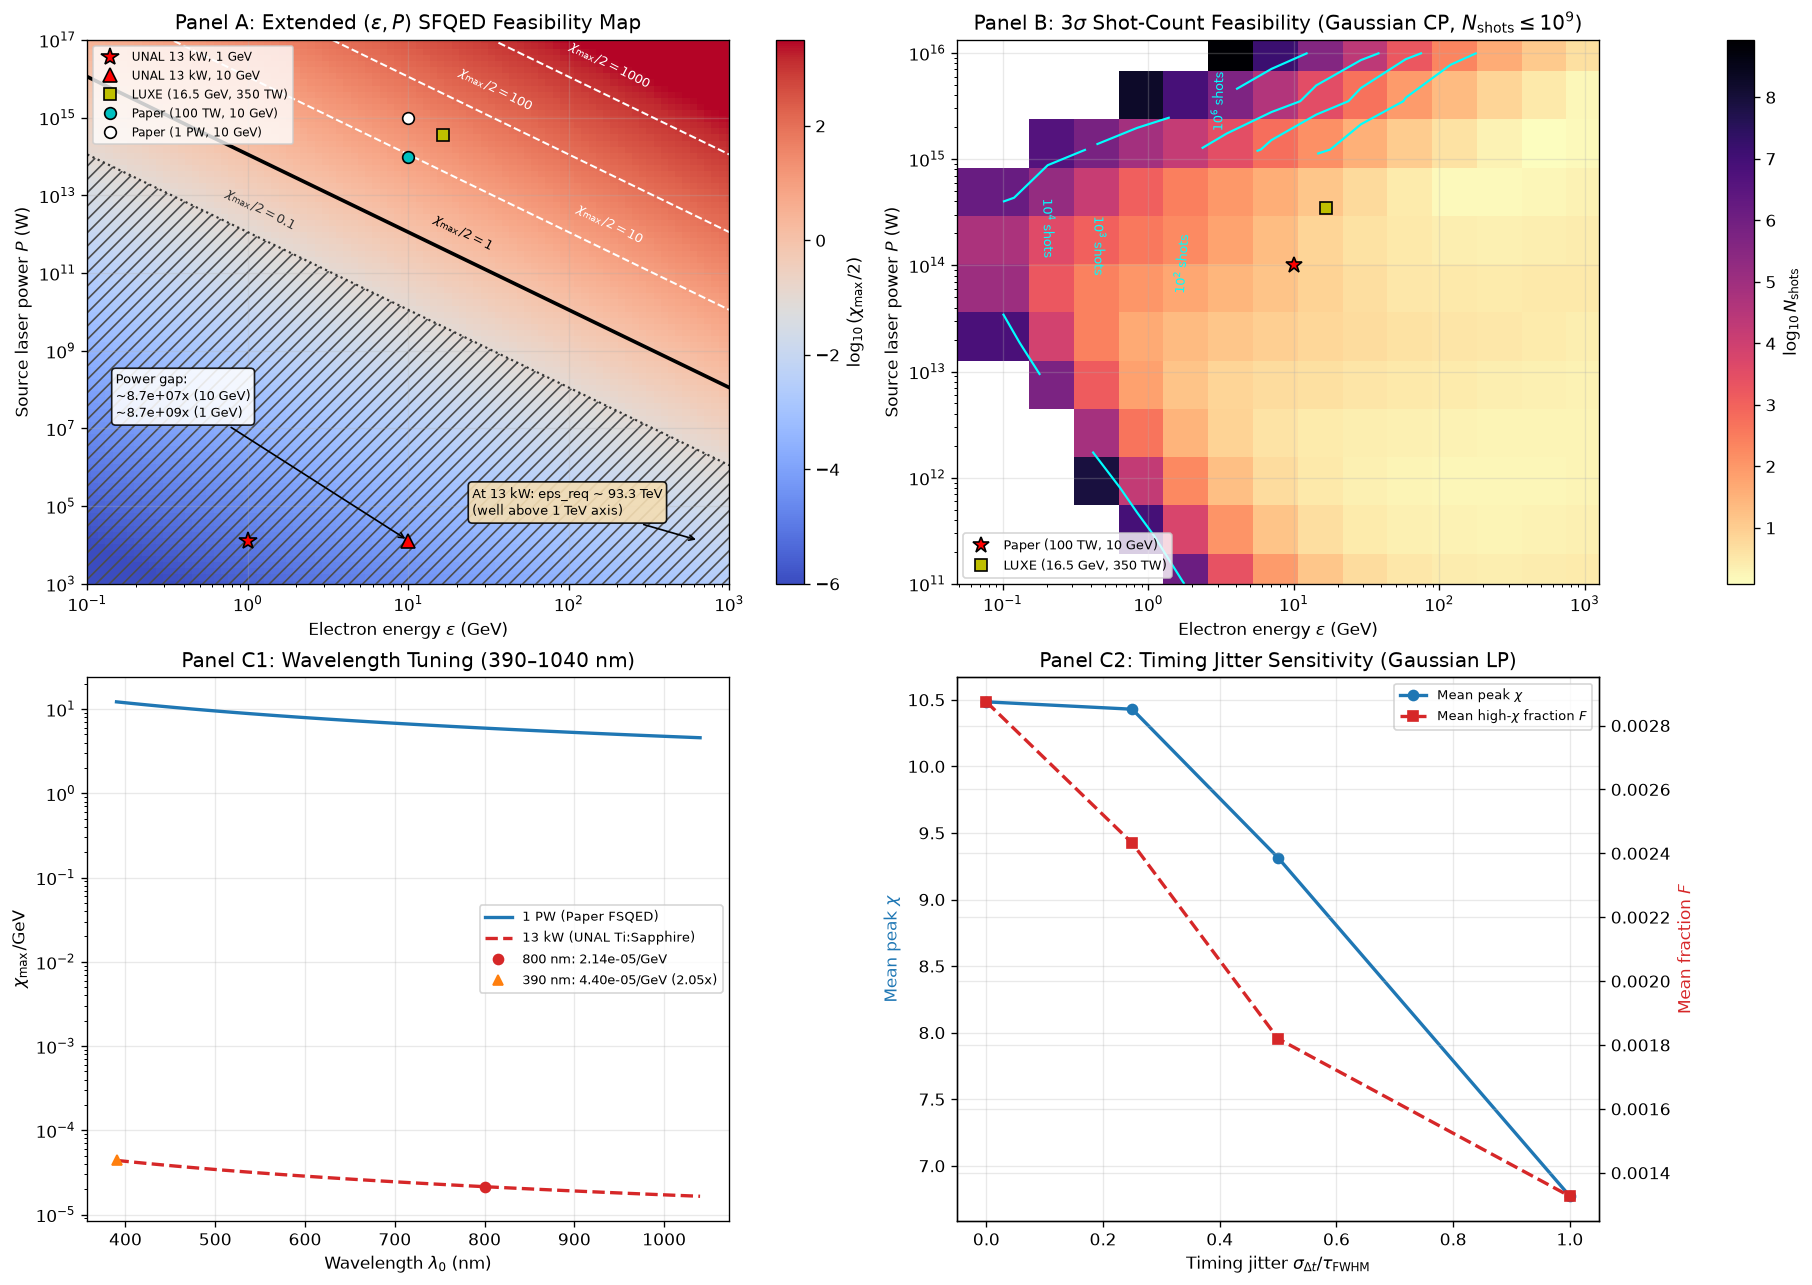

Regime                          |   chi_max |  P(d>0.5) | sigma [cm^2] | eta [%] |   N_shots | P_req/P_UNAL | eps_req [GeV]
---------------------------------------------------------------------------------------------------------------------------
UNAL 800nm / 1 GeV              | 2.144e-05 | 0.000e+00 |    0.000e+00 |    0.00 |       N/A |    8.704e+09 |     9.330e+04
UNAL 800nm / 10 GeV             | 2.144e-04 | 0.000e+00 |    0.000e+00 |    0.00 |       N/A |    8.704e+07 |     9.330e+04
UNAL 390nm / 1 GeV              | 4.397e-05 | 0.000e+00 |    0.000e+00 |    0.00 |       N/A |    2.069e+09 |     4.548e+04
UNAL 390nm / 10 GeV             | 4.397e-04 | 0.000e+00 |    0.000e+00 |    0.00 |       N/A |    2.069e+07 |     4.548e+04
Min SFQED (chi/2=1, 10GeV)      | 2.000e+00 | 8.504e-02 |          N/A |     N/A |       N/A |    8.704e+07 |     1.000e+01
Paper 100TW / 10 GeV (Gauss LP) | 1.880e+01 | 1.722e-01 |    1.374e-12 |   12.08 |    1121.5 |    7.692e+09 |     1.000e+01
Paper 1P

In [9]:
def lcfa_high_energy_tail(tbl, chi_val: float) -> float:
    '''Evaluate P(delta > 0.5 | chi) from LCFATable.high_energy_fraction.'''
    if not math.isfinite(chi_val) or chi_val < 0.0:
        raise ValueError(f"chi_val must be finite and non-negative, got {chi_val}")
    if chi_val < float(tbl.chi_grid[0]):
        return 0.0
    return float(np.interp(chi_val, tbl.chi_grid, tbl.high_energy_fraction))


# Panel A grid: P in [1e3, 1e17] W, eps in [0.1, 1e3] GeV
eps_ext = np.geomspace(0.1, 1000.0, 90)
p_ext = np.geomspace(1.0e3, 1.0e17, 90)
ee_ext, pp_ext = np.meshgrid(eps_ext, p_ext, indexing="xy")

kappa_unal_eff = kappa_eff_fig5  # includes loss T at f=0.25, 0.8 um
chi_max_ext = kappa_unal_eff * ee_ext * np.sqrt(pp_ext / 1.0e15) * (1.0e-6 / 0.8e-6)
chi_half_ext = 0.5 * chi_max_ext
log_chi_half_ext = np.log10(chi_half_ext)

# Exact parameter gaps for UNAL 13 kW at 800 nm
p_unal = float(OC.UNAL_TISAPPHIRE_LASER["power_w"])
chi_unal_1gev = theoretical_chi_max(1.0, p_unal, 0.8e-6, kappa=kappa_unal_eff)
chi_unal_10gev = theoretical_chi_max(10.0, p_unal, 0.8e-6, kappa=kappa_unal_eff)
eps_req_13kw_gev = 2.0 / (kappa_unal_eff * math.sqrt(p_unal / 1.0e15) * (1.0e-6 / 0.8e-6))
p_req_1gev_w = 1.0e15 * ((2.0 * 0.8e-6) / (1.0e-6 * kappa_unal_eff * 1.0)) ** 2
p_req_10gev_w = 1.0e15 * ((2.0 * 0.8e-6) / (1.0e-6 * kappa_unal_eff * 10.0)) ** 2

print(
    f"UNAL 13 kW gap (kappa_eff_net={kappa_unal_eff:.3f}): "
    f"P_req(10 GeV)/P_UNAL = {p_req_10gev_w / p_unal:.2e}x, "
    f"P_req(1 GeV)/P_UNAL = {p_req_1gev_w / p_unal:.2e}x, "
    f"eps_req(13 kW) = {eps_req_13kw_gev / 1000.0:.2f} TeV"
)

# Panel B: 3-sigma shot-count grid from Section 7 Realistic Gaussian CP
tau_5cycle_s = base_packs[("gaussian", "circular")].pulse.tau_fwhm_s
sig_cp = scan_results[("gaussian", "circular")]["sigma_cm2"]
eta_cp = scan_results[("gaussian", "circular")]["eta"]
n_shots_grid = np.full_like(sig_cp, np.nan, dtype=np.float64)

for ip in range(p_scan.size):
    for ie in range(eps_scan.size):
        if sig_cp[ip, ie] > 0.0 and eta_cp[ip, ie] > 0.0:
            est = estimate_shots_for_confidence(
                sigma_cm2=float(sig_cp[ip, ie]),
                eta=float(eta_cp[ip, ie]),
                tau_l_s=tau_5cycle_s,
            )
            if est.n_shots_required <= 1.0e9:
                n_shots_grid[ip, ie] = est.n_shots_required

log_shots_masked = np.ma.masked_where(~np.isfinite(n_shots_grid), np.log10(np.where(np.isfinite(n_shots_grid), n_shots_grid, 1.0)))

# Panel C1: Wavelength sweep 390 - 1040 nm
lambdas_m = np.linspace(390.0e-9, 1040.0e-9, 40)
chi_lam_13kw = np.array([theoretical_chi_max(1.0, p_unal, float(lam), kappa=kappa_unal_eff) for lam in lambdas_m])
chi_lam_1pw = np.array([theoretical_chi_max(1.0, 1.0e15, float(lam), kappa=kappa_unal_eff) for lam in lambdas_m])
gain_390 = (800.0e-9 / 390.0e-9)
print(f"Wavelength tuning 800 nm -> 390 nm gain factor: {gain_390:.2f}x")

# Panel C2: Timing jitter sweep on loaded_gauss_lp
jitter_fracs = [0.0, 0.25, 0.5, 1.0]
jitter_peak_chi = []
jitter_mean_f = []
tau_fwhm_glp = loaded_gauss_lp.pulse.tau_fwhm_s
chi_max_glp_ref = loaded_gauss_lp.checks.chi_max_per_GeV * cfg["energy_gev"]

for frac_j in jitter_fracs:
    batch_j = sample_electron_batch(
        n_particles=300,
        energy_gev=cfg["energy_gev"],
        b_max_m=1.5 * loaded_gauss_lp.lambda0_m,
        y0_m=loaded_gauss_lp.grid.y0_m,
        sigma_dt_s=frac_j * tau_fwhm_glp,
        jitter_mode="per_particle",
        rng=np.random.default_rng(42),
    )
    traj_j = propagate_ensemble(loaded_gauss_lp, batch_j, method="vay", signed_alpha=True)
    dt_j = float(traj_j.t_s[1] - traj_j.t_s[0])
    f_j = compute_high_chi_time_fraction(traj_j.chi, dt_j, chi_max=chi_max_glp_ref)
    jitter_peak_chi.append(float(np.mean(np.max(traj_j.chi, axis=1))))
    jitter_mean_f.append(float(np.mean(f_j)))

# 2x2 Feasibility & Sensitivity Figure
fig, axes = plt.subplots(2, 2, figsize=(15.0, 10.6), constrained_layout=True)

# Panel A
ax_a = axes[0, 0]
im_a = ax_a.pcolormesh(eps_ext, p_ext, log_chi_half_ext, cmap="coolwarm", vmin=-6.0, vmax=3.5, shading="auto")
def _p_for_chi_half(lvl: float, eps_arr: np.ndarray) -> np.ndarray:
    return 1.0e15 * ((2.0 * lvl * 0.8e-6) / (1.0e-6 * kappa_unal_eff * eps_arr)) ** 2

p_sub_01 = np.clip(_p_for_chi_half(0.1, eps_ext), p_ext.min(), p_ext.max())
ax_a.fill_between(
    eps_ext, p_ext.min(), p_sub_01,
    facecolor="none", edgecolor="0.3", hatch="///", linewidth=0.0,
)
contour_styles = [
    (0.1, "0.2", ":", 1.3, 1.2),
    (1.0, "black", "-", 2.2, 22.0),
    (10.0, "white", "--", 1.2, 180.0),
    (100.0, "white", "--", 1.2, 35.0),
    (1000.0, "white", "--", 1.2, 180.0),
]
for lvl, col, ls, lw, x_lbl in contour_styles:
    p_line = _p_for_chi_half(lvl, eps_ext)
    mask_line = (p_line >= p_ext.min()) & (p_line <= p_ext.max())
    ax_a.plot(eps_ext[mask_line], p_line[mask_line], color=col, ls=ls, lw=lw)
    y_lbl = float(_p_for_chi_half(lvl, np.array([x_lbl]))[0]) * 1.35
    if p_ext.min() <= y_lbl <= p_ext.max():
        ax_a.text(x_lbl, y_lbl, rf"$\chi_{{\max}}/2={lvl:g}$", color=col, fontsize=7.5, rotation=-27, ha="center", va="bottom")
ax_a.set_xlim(eps_ext.min(), eps_ext.max())
ax_a.set_ylim(p_ext.min(), p_ext.max())

ax_a.plot(1.0, p_unal, "r*", ms=11, markeredgecolor="k", label="UNAL 13 kW, 1 GeV")
ax_a.plot(10.0, p_unal, "r^", ms=8, markeredgecolor="k", label="UNAL 13 kW, 10 GeV")
ax_a.plot(16.5, 350.0e12, "ys", ms=7, markeredgecolor="k", label="LUXE (16.5 GeV, 350 TW)")
ax_a.plot(10.0, 100.0e12, "co", ms=7, markeredgecolor="k", label="Paper (100 TW, 10 GeV)")
ax_a.plot(10.0, 1.0e15, "wo", ms=7, markeredgecolor="k", label="Paper (1 PW, 10 GeV)")

ax_a.annotate(
    f"Power gap:\n~{p_req_10gev_w/p_unal:.1e}x (10 GeV)\n~{p_req_1gev_w/p_unal:.1e}x (1 GeV)",
    xy=(10.0, p_unal),
    xytext=(0.15, 2.0e7),
    color="black",
    fontsize=7.8,
    bbox=dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.88),
    arrowprops=dict(arrowstyle="->", color="black", lw=1.0),
)
ax_a.annotate(
    f"At 13 kW: eps_req ~ {eps_req_13kw_gev/1000.0:.1f} TeV\n(well above 1 TeV axis)",
    xy=(650.0, p_unal),
    xytext=(25.0, 6.0e4),
    color="black",
    fontsize=7.8,
    bbox=dict(boxstyle="round,pad=0.3", facecolor="wheat", alpha=0.9),
    arrowprops=dict(arrowstyle="->", color="black", lw=1.0),
)
ax_a.set_xscale("log")
ax_a.set_yscale("log")
ax_a.set_xlabel(r"Electron energy $\varepsilon$ (GeV)")
ax_a.set_ylabel(r"Source laser power $P$ (W)")
ax_a.set_title(r"Panel A: Extended $(\varepsilon, P)$ SFQED Feasibility Map")
ax_a.legend(fontsize=7.2, loc="upper left")
fig.colorbar(im_a, ax=ax_a, label=r"$\log_{10}(\chi_{\max} / 2)$")

# Panel B
ax_b = axes[0, 1]
cmap_sh = plt.cm.magma_r.copy()
cmap_sh.set_bad("white")
im_b = ax_b.pcolormesh(eps_scan, p_scan, log_shots_masked, cmap=cmap_sh, shading="auto")
valid_shot_levels = [
    lv for lv in (2.0, 3.0, 4.0, 6.0)
    if np.nanmin(log_shots_masked) < lv < np.nanmax(log_shots_masked)
]
if valid_shot_levels:
    cs_b = ax_b.contour(
        eps_scan,
        p_scan,
        np.where(np.isfinite(n_shots_grid), np.log10(np.where(np.isfinite(n_shots_grid), n_shots_grid, 1.0)), np.nan),
        levels=valid_shot_levels,
        colors="cyan",
        linewidths=1.3,
    )
    ax_b.clabel(cs_b, fmt=lambda v: rf"$10^{{{int(round(v))}}}$ shots", fontsize=7.5)
ax_b.plot(10.0, 100.0e12, "r*", ms=10, markeredgecolor="k", label="Paper (100 TW, 10 GeV)")
ax_b.plot(16.5, 350.0e12, "ys", ms=7, markeredgecolor="k", label="LUXE (16.5 GeV, 350 TW)")
ax_b.set_xscale("log")
ax_b.set_yscale("log")
ax_b.set_xlabel(r"Electron energy $\varepsilon$ (GeV)")
ax_b.set_ylabel(r"Source laser power $P$ (W)")
ax_b.set_title(r"Panel B: $3\sigma$ Shot-Count Feasibility (Gaussian CP, $N_{\mathrm{shots}} \leq 10^9$)")
ax_b.legend(fontsize=7.5, loc="lower left")
fig.colorbar(im_b, ax=ax_b, label=r"$\log_{10} N_{\mathrm{shots}}$")

# Panel C1: Wavelength tuning
ax_c1 = axes[1, 0]
ax_c1.semilogy(lambdas_m * 1.0e9, chi_lam_1pw, "C0-", lw=2.0, label=r"$1\ \mathrm{PW}$ (Paper FSQED)")
ax_c1.semilogy(lambdas_m * 1.0e9, chi_lam_13kw, "C3--", lw=2.0, label=r"$13\ \mathrm{kW}$ (UNAL Ti:Sapphire)")
ax_c1.plot(800.0, chi_unal_1gev, "C3o", ms=6, label=rf"800 nm: {chi_unal_1gev:.2e}/GeV")
ax_c1.plot(390.0, chi_lam_13kw[0], "C1^", ms=6, label=rf"390 nm: {chi_lam_13kw[0]:.2e}/GeV ({gain_390:.2f}x)")
ax_c1.set_xlabel(r"Wavelength $\lambda_0$ (nm)")
ax_c1.set_ylabel(r"$\chi_{\max} / \mathrm{GeV}$")
ax_c1.set_title(r"Panel C1: Wavelength Tuning (390–1040 nm)")
ax_c1.legend(fontsize=8)

# Panel C2: Timing jitter
ax_c2 = axes[1, 1]
ax_c2_r = ax_c2.twinx()
lc1 = ax_c2.plot(jitter_fracs, jitter_peak_chi, "C0o-", lw=2.0, label=r"Mean peak $\chi$")
lc2 = ax_c2_r.plot(jitter_fracs, jitter_mean_f, "C3s--", lw=2.0, label=r"Mean high-$\chi$ fraction $F$")
ax_c2.set_xlabel(r"Timing jitter $\sigma_{\Delta t} / \tau_{\mathrm{FWHM}}$")
ax_c2.set_ylabel(r"Mean peak $\chi$", color="C0")
ax_c2_r.set_ylabel(r"Mean fraction $F$", color="C3")
ax_c2.set_title(r"Panel C2: Timing Jitter Sensitivity (Gaussian LP)")
lines_c2 = lc1 + lc2
ax_c2.legend(lines_c2, [ln.get_label() for ln in lines_c2], loc="upper right", fontsize=8)

plt.show()

# Quantitative Feasibility Gap Table
gap_rows = []
unal_specs = [
    ("UNAL 800nm / 1 GeV", 0.8e-6, p_unal, 1.0, loaded_campus_gauss),
    ("UNAL 800nm / 10 GeV", 0.8e-6, p_unal, 10.0, loaded_campus_gauss),
    ("UNAL 390nm / 1 GeV", 0.39e-6, p_unal, 1.0, None),
    ("UNAL 390nm / 10 GeV", 0.39e-6, p_unal, 10.0, None),
]
for label, lam, pwr, eps, pk_opt in unal_specs:
    chi_v = theoretical_chi_max(eps, pwr, lam, kappa=kappa_unal_eff)
    p_req = 1.0e15 * ((2.0 * lam) / (1.0e-6 * kappa_unal_eff * eps)) ** 2
    eps_req = 2.0 / (kappa_unal_eff * math.sqrt(pwr / 1.0e15) * (1.0e-6 / lam))
    if pk_opt is not None:
        ev = evaluate_qed_point(pk_opt, energy_gev=eps, n_particles=200, b_max_lambdas=1.5, table=table)
        sig_v, eta_v, nsh_v = ev["sigma_cm2"], ev["eta"], ev["n_shots"]
    else:
        sig_v, eta_v, nsh_v = 0.0, 0.0, None
    gap_rows.append((label, chi_v, lcfa_high_energy_tail(table, chi_v), sig_v, eta_v, nsh_v, p_req / p_unal, eps_req))

# Min SFQED threshold chi_max/2 = 1 at 10 GeV, 800 nm
p_min_10 = 1.0e15 * ((2.0 * 0.8e-6) / (1.0e-6 * kappa_unal_eff * 10.0)) ** 2
gap_rows.append(("Min SFQED (chi/2=1, 10GeV)", 2.0, lcfa_high_energy_tail(table, 2.0), float("nan"), float("nan"), None, p_min_10 / p_unal, 10.0))

for label, pk in (("Paper 100TW / 10 GeV (Gauss LP)", loaded_100tw_gauss_lp), ("Paper 1PW / 10 GeV (Gauss LP)", loaded_gauss_lp)):
    ev = evaluate_qed_point(pk, energy_gev=10.0, n_particles=600, b_max_lambdas=1.5, table=table)
    p_src_v = pk.power_W / t_loss_fig5
    gap_rows.append((
        label,
        ev["chi_max"],
        lcfa_high_energy_tail(table, ev["chi_max"]),
        ev["sigma_cm2"],
        ev["eta"],
        ev["n_shots"],
        p_src_v / p_unal,
        10.0,
    ))

ghdr = (
    f"{'Regime':31s} | {'chi_max':>9s} | {'P(d>0.5)':>9s} | {'sigma [cm^2]':>12s} | "
    f"{'eta [%]':>7s} | {'N_shots':>9s} | {'P_req/P_UNAL':>12s} | {'eps_req [GeV]':>13s}"
)
print(ghdr)
print("-" * len(ghdr))
for label, chi_v, tail_v, sig_v, eta_v, nsh_v, p_mult, eps_req in gap_rows:
    sig_s = "N/A" if not math.isfinite(sig_v) else f"{sig_v:12.3e}"
    eta_s = "N/A" if not math.isfinite(eta_v) else f"{100.0 * eta_v:7.2f}"
    nsh_s = "N/A" if nsh_v is None else f"{nsh_v:9.1f}"
    print(
        f"{label:31s} | {chi_v:9.3e} | {tail_v:9.3e} | {sig_s:>12s} | "
        f"{eta_s:>7s} | {nsh_s:>9s} | {p_mult:12.3e} | {eps_req:13.3e}"
    )

print(f"\nTotal notebook wall time: {time.perf_counter() - t_notebook_start:.2f} s")